# 第一步：多维度数据全景抓取与增强型 EDA 分析

## 1.1 爬取前沿特征字典 (包含相变/无序/高维晶组空间)
本步骤基于第一套原始人工探索方案，从 Material Project API 直接下载带有 `H` 的原始结构宽表。
为了更好的探究物理特征的强相关性，相较于先前的粗糙抓取，新增了结晶类型(Crystal System)、空间群对称性(Spacegroup) 与 热力学脱离底包稳定系数(Energy Above Hull)。这些特征是物理和材料学界验证是否“能被制备出来”的底盘因子。

In [1]:
!pip install -q mp-api pandas matplotlib seaborn missingno matminer

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import re
import warnings
from mp_api.client import MPRester

warnings.filterwarnings("ignore")
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial']
plt.rcParams['axes.unicode_minus'] = False

api_key = os.environ["MP_API_KEY"]

# 严格圈定可以用于组成有效储氢合金的金属元素池
allowed_elements = [
    'Li', 'Na', 'K', 'Rb', 'Cs', 'Be', 'Mg', 'Ca', 'Sr', 'Ba',
    'Sc', 'Ti', 'V', 'Cr', 'Mn', 'Fe', 'Co', 'Ni', 'Cu', 'Zn',
    'Y', 'Zr', 'Nb', 'Mo', 'Tc', 'Ru', 'Rh', 'Pd', 'Ag', 'Cd',
    'Hf', 'Ta', 'W', 'Re', 'Os', 'Ir', 'Pt', 'Au', 'Hg',
    'La', 'Ce', 'Pr', 'Nd', 'Pm', 'Sm', 'Eu', 'Gd', 'Tb', 'Dy', 'Ho', 'Er', 'Tm', 'Yb', 'Lu',
    'B', 'Al', 'Ga', 'In', 'Tl', 'Si', 'Ge', 'Sn', 'Pb', 'As', 'Sb', 'Bi', 'Te', 'Po',
    'Ne', 'Ar', 'Kr', 'Xe', 'Rn'
]
allowed_set = set(allowed_elements + ["H"])
cache_file = "MP_Hydrogen_Alloys_Cache.pkl"
import os

if os.path.exists(cache_file):
    print(f"📦 检测到本地缓存文件 {cache_file}，直接加载以保证数据顺序和内容100%一致...")
    df = pd.read_pickle(cache_file)
else:
    results_data = []

    print("🚀 正在连接 Materials Project 数据库，抓取增强版金属氢化物特征...")
    with MPRester(api_key) as mpr:
        # 抓取特征相较于原版大幅增强：加入了 symmetry(晶系/空间群), energy_above_hull等
        docs = mpr.summary.search(
            elements=["H"],
            num_elements=(2, 6),
            fields=[
                "material_id", "formula_pretty", "formation_energy_per_atom",
                "energy_above_hull", "band_gap", "density", "volume", "nsites",
                "total_magnetization", "elements", "symmetry"
            ]
        )

        for doc in docs:
            doc_elements = [el.symbol for el in doc.elements]
            # 脏数据拦截：存在黑名单元素直接跳过
            if not all(el in allowed_set for el in doc_elements):
                continue

            atomic_volume = doc.volume / doc.nsites if doc.nsites else None

            results_data.append({
                "Material ID": doc.material_id,
                "Formula": doc.formula_pretty,
                "Formation Energy (eV/atom)": doc.formation_energy_per_atom,
                "Energy Above Hull (eV/atom)": doc.energy_above_hull, # 新增：热力学稳定性关键指标
                "Crystal System": doc.symmetry.crystal_system.name if doc.symmetry else None, # 新增：晶系
                "Spacegroup": doc.symmetry.number if doc.symmetry else None, # 新增：空间群编号
                "Band Gap (eV)": doc.band_gap,
                "Density (g/cm³)": doc.density,
                "Atomic Volume (Å³/atom)": atomic_volume,
                "Total Magnetization (μB)": doc.total_magnetization
            })

    df = pd.DataFrame(results_data)
    # 落盘保存！
    df.to_pickle(cache_file)
    print(f"💾 抓取完毕！数据已保存至本地缓存 {cache_file}，下次运行将直接读取。")

# 第一步修改点：直接输出前 5 行，展示抓取到了哪些数据，免去重复运行
print(f"✅ 初步抓取完成！共获得 {len(df)} 条增强记录。以下为数据概览：")
display(df.head())

🚀 正在连接 Materials Project 数据库，抓取增强版金属氢化物特征...


Retrieving SummaryDoc documents:   0%|          | 0/10263 [00:00<?, ?it/s]

💾 抓取完毕！数据已保存至本地缓存 MP_Hydrogen_Alloys_Cache.pkl，下次运行将直接读取。
✅ 初步抓取完成！共获得 911 条增强记录。以下为数据概览：


,Material ID,Formula,Formation Energy (eV/atom),Energy Above Hull (eV/atom),Crystal System,Spacegroup,Band Gap (eV),Density (g/cm³),Atomic Volume (Å³/atom),Total Magnetization (μB)
0,mp-632311,Ta2H,-0.136438,0.040393,tet,115,0.0,15.537626,12.928096,1.000000e-07
1,mp-632219,ZrH,-0.395258,0.096271,tet,119,0.0,5.657335,13.535944,4.307200e-03
2,mp-1217971,Ta2H,-0.107646,0.069185,mono,12,0.0,15.777973,12.731162,0.000000e+00
3,mp-642644,V2H,-0.170593,0.000055,mono,12,0.0,5.978561,9.525951,4.600000e-06
4,mp-690760,TiH,-0.408515,0.001702,tet,131,0.0,4.089972,9.921675,1.400000e-06


## 1.2 组分复杂度分布诊断与严格剔除机制
在进入极重度运算前，我们需要观察当前采集到的候选材料成分复杂度（如二元、三元等）。
过于繁杂的五元六元多组配方不仅物理制备困难、缺乏普遍性，同时在加权推波时含有巨大的白噪声干扰。
此外，本步废弃了乱码的矩阵图直观分析，采用更严谨彻底的终端文字断层扫描，精确剥离空值。

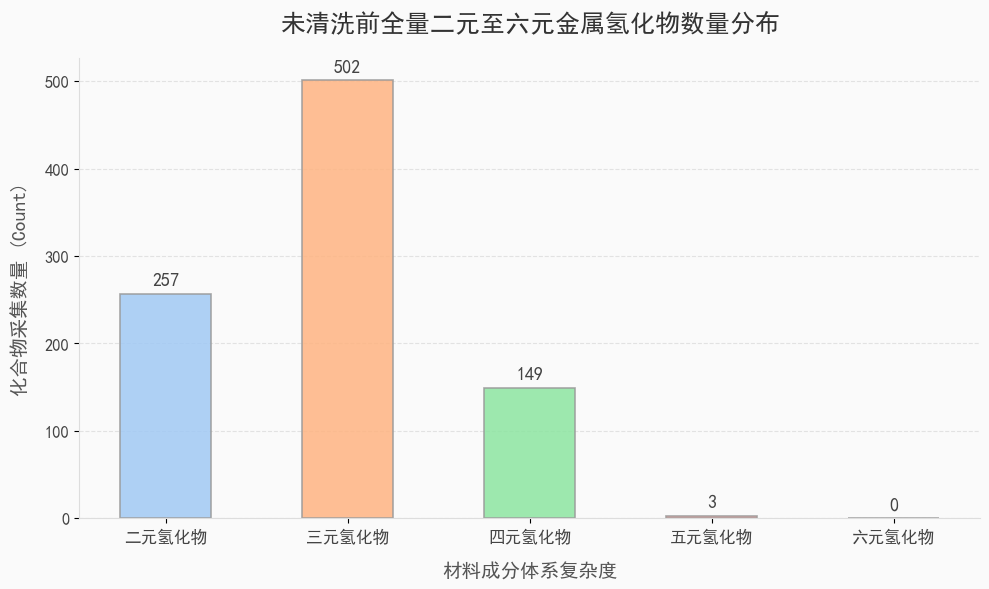

🗑️ 经过图表分析论证，剔除极少数且缺乏普遍意义的五/六元极端组分后，剩余核心二/三/四元数据：908 条。

 🕵️‍♂️ 数据缺失值探测 (直接纯文字结论输出，不渲染方块错位图)
【审查结果】发现以下核心特征存在缺失情况（空值单元格数）：
Series([], dtype: int64)

✅ 净化机制运作完毕 (已将含有任何一列 NaN 的瑕疵记录全部截断清洗)：
 -> 净化前全量样本：908
 -> 净化后高维完整纯净级样本：908


,Material ID,Formula,Formation Energy (eV/atom),Energy Above Hull (eV/atom),Crystal System,Spacegroup,Band Gap (eV),Density (g/cm³),Atomic Volume (Å³/atom),Total Magnetization (μB),Num Elements
0,mp-632311,Ta2H,-0.136438,0.040393,tet,115,0.0000,15.537626,12.928096,1.000000e-07,2
1,mp-632219,ZrH,-0.395258,0.096271,tet,119,0.0000,5.657335,13.535944,4.307200e-03,2
2,mp-1217971,Ta2H,-0.107646,0.069185,mono,12,0.0000,15.777973,12.731162,0.000000e+00,2
3,mp-642644,V2H,-0.170593,0.000055,mono,12,0.0000,5.978561,9.525951,4.600000e-06,2
4,mp-690760,TiH,-0.408515,0.001702,tet,131,0.0000,4.089972,9.921675,1.400000e-06,2
...,...,...,...,...,...,...,...,...,...,...,...
906,mp-1195647,NaY(BH4)4,-0.339838,0.008090,ortho,63,5.8185,1.145602,11.284066,1.448000e-04,4
907,mp-1197756,KY(BH4)4,-0.366537,0.000085,ortho,63,6.0454,1.085319,13.031106,8.475000e-04,4
908,mp-866649,NaSc(BH4)4,-0.389034,0.000000,ortho,63,4.8657,0.996330,9.645139,1.061100e-03,4
909,mp-1195284,KAl(BH4)4,-0.315427,0.000000,ortho,70,6.6466,0.839434,11.280122,4.336700e-03,4



 🔄 二次清洗：按 Formula 去重 (保留 Energy Above Hull 最低的条目)

去重前样本数: 908
去重前唯一化学式数: 673

去重后样本数: 673
去重后唯一化学式数: 673
共剔除 235 条重复 Formula 记录 (保留了热力学最稳定的多型体)


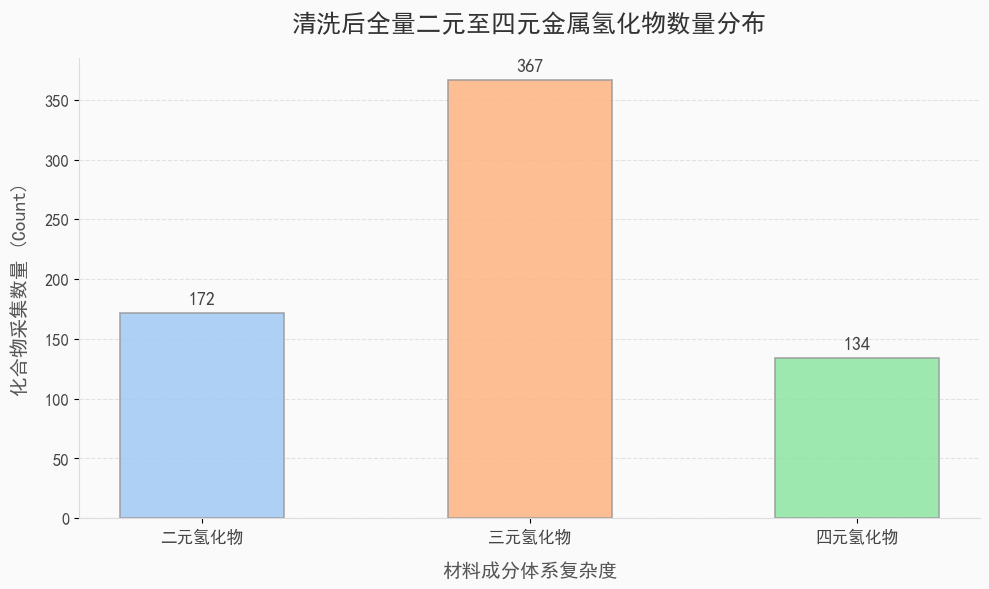


✅ 二次清洗完毕！去重后剩余 673 条唯一化学式记录，后续所有步骤均基于此数据。


,Material ID,Formula,Formation Energy (eV/atom),Energy Above Hull (eV/atom),Crystal System,Spacegroup,Band Gap (eV),Density (g/cm³),Atomic Volume (Å³/atom),Total Magnetization (μB),Num Elements
0,mp-1213828,CeMg(NiH)4,-0.355078,0.000000,ortho,31,0.0000,6.735206,9.941391,0.090535,4
1,mp-23715,BaH2,-0.604747,0.000000,ortho,62,2.8697,4.102443,18.800528,0.000000,2
2,mp-23714,SrH2,-0.647580,0.000000,ortho,62,3.1544,3.332787,14.886829,0.000000,2
3,mp-23713,CaH2,-0.666882,0.000000,ortho,62,3.0275,1.960743,11.882999,0.000000,2
4,mp-31096,Li3AlH6,-0.355518,0.000000,trig,148,3.5929,1.042497,8.577829,0.000000,3
...,...,...,...,...,...,...,...,...,...,...,...
668,mp-1187975,Yb3H,0.749286,1.049186,hex_,194,0.0000,8.602979,25.098654,3.476384,2
669,mp-1184653,HW3,1.089287,1.089287,hex_,194,0.0000,15.928071,14.400586,0.004566,2
670,mp-1184938,KH3,0.960021,1.104807,tet,139,0.0000,1.287692,13.579611,1.075640,2
671,mp-1213995,Ce2Si2HRu,0.586314,1.306388,tet,123,0.0000,6.599088,18.389278,0.497357,4


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# 计算每一个配方包含的元素数量
def count_elements(formula):
    return len(re.findall(r'[A-Z]', formula))
df['Num Elements'] = df['Formula'].apply(count_elements)

# 第二步修改点 1：剔除多元素金属材料之前，加入其数量分布的高阶可视化大图
element_counts = {i: (df['Num Elements'] == i).sum() for i in range(2, 7)}
names = {2: '二元', 3: '三元', 4: '四元', 5: '五元', 6: '六元'}

labels = [f'{names[i]}氢化物' for i in range(2, 7)]
counts = [element_counts[i] for i in range(2, 7)]

fig, ax = plt.subplots(figsize=(10, 6), facecolor='#FAFAFA')
colors = sns.color_palette("pastel", len(labels))
bars = ax.bar(labels, counts, color=colors, edgecolor='#999999', linewidth=1.2, alpha=0.85, width=0.5)

ax.set_title('未清洗前全量二元至六元金属氢化物数量分布', fontsize=18, fontweight='bold', pad=20, color='#333333')
ax.set_ylabel('化合物采集数量 (Count)', fontsize=14, labelpad=12, color='#555555')
ax.set_xlabel('材料成分体系复杂度', fontsize=14, labelpad=12, color='#555555')
plt.xticks(fontsize=12, color='#444444')
plt.yticks(fontsize=12, color='#444444')
ax.grid(axis='y', linestyle='--', alpha=0.5, color='#CCCCCC')
ax.set_axisbelow(True)
ax.set_facecolor('#FAFAFA')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_color('#DDDDDD')
ax.spines['left'].set_color('#DDDDDD')

for i, v in enumerate(counts):
    ax.text(i, v + max(counts)*0.015, f"{v}", ha='center', va='bottom', fontsize=13, fontweight='bold', color='#444444')

plt.tight_layout()
plt.show()

# 基于由简到繁与统计学意义，剔除极小样本配方
df_filtered = df[df['Num Elements'] <= 4].copy()
print(f'🗑️ 经过图表分析论证，剔除极少数且缺乏普遍意义的五/六元极端组分后，剩余核心二/三/四元数据：{len(df_filtered)} 条。\n')

print("==========================================")
print(" 🕵️‍♂️ 数据缺失值探测 (直接纯文字结论输出，不渲染方块错位图)")
print("==========================================")

# 筛选必须要完整的核心特征群
columns_to_check = [
    "Formation Energy (eV/atom)", "Energy Above Hull (eV/atom)", 
    "Crystal System", "Band Gap (eV)", "Density (g/cm³)", 
    "Atomic Volume (Å³/atom)", "Total Magnetization (μB)"
]

# 第二步修改点 2：取消错位的 missingno 的图表绘制，将其变为静默直接检测剔除并用文字总结
null_counts_filtered = df_filtered[columns_to_check].isnull().sum()
print("【审查结果】发现以下核心特征存在缺失情况（空值单元格数）：")
print(null_counts_filtered[null_counts_filtered > 0])

null_before = len(df_filtered)
df_clean = df_filtered.dropna(subset=columns_to_check).copy()
print(f"\n✅ 净化机制运作完毕 (已将含有任何一列 NaN 的瑕疵记录全部截断清洗)：")
print(f" -> 净化前全量样本：{null_before}")
print(f" -> 净化后高维完整纯净级样本：{len(df_clean)}")

# 显示清洗结果与表头以自查
display(df_clean)

# =====================================================
# 🔄 二次清洗：按 Formula 去重，保留 Energy Above Hull 最小的条目
# 同一化学式可能对应多种不同的晶体结构(多型体)，保留热力学最稳定的那个
# =====================================================
print("\n==========================================")
print(" 🔄 二次清洗：按 Formula 去重 (保留 Energy Above Hull 最低的条目)")
print("==========================================")

print(f"\n去重前样本数: {len(df_clean)}")
print(f"去重前唯一化学式数: {df_clean['Formula'].nunique()}")

# 按 Energy Above Hull 升序排列，对 Formula 去重（保留第一个即最小的）
num_before_dedup = len(df_clean)
df_clean = df_clean.sort_values('Energy Above Hull (eV/atom)').drop_duplicates(subset='Formula', keep='first').reset_index(drop=True)

# 同步更新 df_filtered，确保后续所有步骤用的都是去重后的数据
df_filtered = df_clean.copy()

print(f"\n去重后样本数: {len(df_clean)}")
print(f"去重后唯一化学式数: {df_clean['Formula'].nunique()}")
print(f"共剔除 {num_before_dedup - len(df_clean)} 条重复 Formula 记录 (保留了热力学最稳定的多型体)")

# === 绘制清洗后全量二元至四元金属氢化物数量分布图 ===
element_counts_after = {i: (df_clean['Num Elements'] == i).sum() for i in range(2, 5)}
names_after = {2: '二元', 3: '三元', 4: '四元'}

labels_after = [f'{names_after[i]}氢化物' for i in range(2, 5)]
counts_after = [element_counts_after[i] for i in range(2, 5)]

fig, ax = plt.subplots(figsize=(10, 6), facecolor='#FAFAFA')
colors = sns.color_palette("pastel", len(labels_after))
bars = ax.bar(labels_after, counts_after, color=colors, edgecolor='#999999', linewidth=1.2, alpha=0.85, width=0.5)

ax.set_title('清洗后全量二元至四元金属氢化物数量分布', fontsize=18, fontweight='bold', pad=20, color='#333333')
ax.set_ylabel('化合物采集数量 (Count)', fontsize=14, labelpad=12, color='#555555')
ax.set_xlabel('材料成分体系复杂度', fontsize=14, labelpad=12, color='#555555')
plt.xticks(fontsize=12, color='#444444')
plt.yticks(fontsize=12, color='#444444')
ax.grid(axis='y', linestyle='--', alpha=0.5, color='#CCCCCC')
ax.set_axisbelow(True)
ax.set_facecolor('#FAFAFA')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_color('#DDDDDD')
ax.spines['left'].set_color('#DDDDDD')

for i, v in enumerate(counts_after):
    ax.text(i, v + max(counts_after)*0.015, f"{v}", ha='center', va='bottom', fontsize=13, fontweight='bold', color='#444444')

plt.tight_layout()
plt.show()

print(f"\n✅ 二次清洗完毕！去重后剩余 {len(df_clean)} 条唯一化学式记录，后续所有步骤均基于此数据。")
display(df_clean)

## 1.3 晶系构效靶向探索：高级混频下探图
**这是第一阶段优化的核心图景。** 纯化学式的生成能只能告诉我们元素搭在一起热力学能不能稳得住（Formation Energy）；
但是空间框架（Crystal System 立方、六方体系）会实质决定能否吸纳大含量的氢源。
通过此图表，肉眼甄别哪类晶系天生掉落在我们的热力学最佳释放区域 $[-0.5, 0]$ eV。

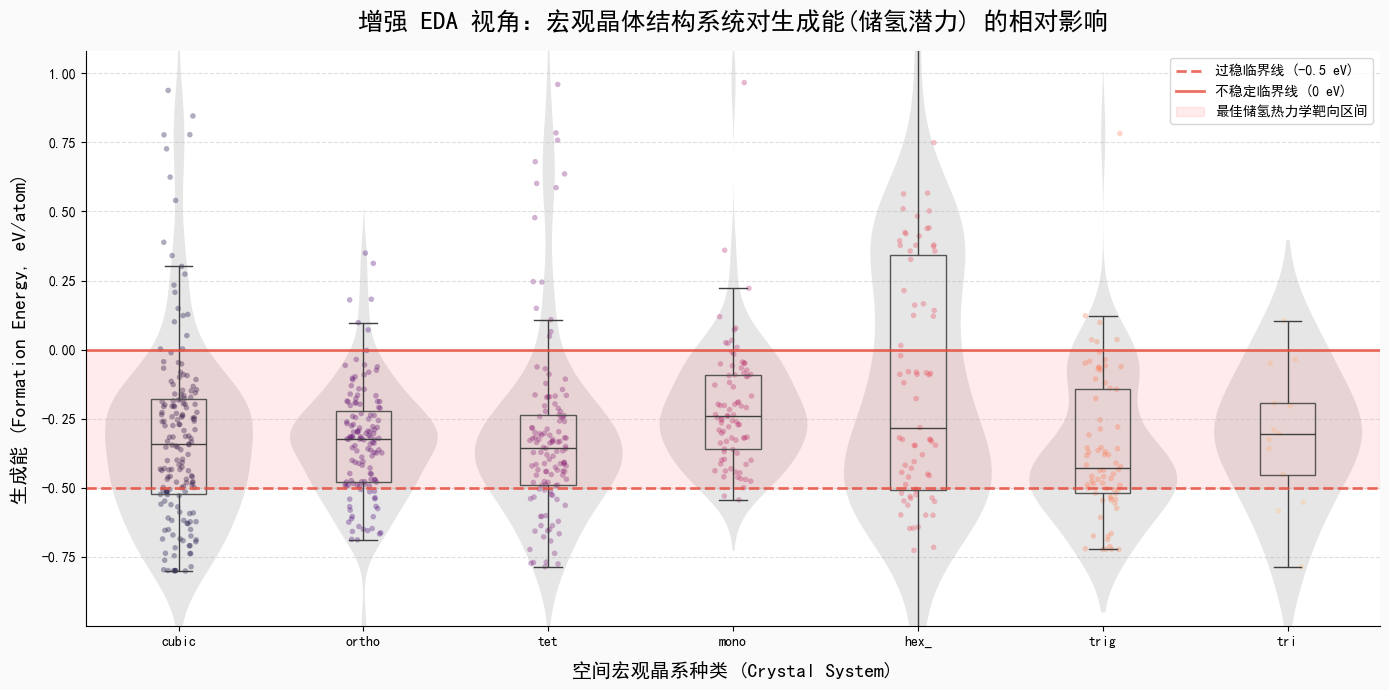

In [3]:
# --- 晶系分布 vs 形成能下探分析 ---
# 提取有价值的材料绘制全新视角的“特定空间结构分布图”
plt.figure(figsize=(14, 7), facecolor='#FAFAFA')

# 美化顺序，根据每种晶系的材料数量降序摆放
order = df_clean['Crystal System'].value_counts().index

# 绘制带有抖动散点覆盖的优雅小提琴/箱线混合图
sns.violinplot(
    x="Crystal System", y="Formation Energy (eV/atom)", 
    data=df_clean, order=order, 
    inner=None, color=".9", linewidth=0, scale="width"
)
sns.boxplot(
    x="Crystal System", y="Formation Energy (eV/atom)", 
    data=df_clean, order=order,
    width=0.3, fliersize=0, boxprops={'facecolor': 'none', 'edgecolor': '#555555'}
)
sns.stripplot(
    x="Crystal System", y="Formation Energy (eV/atom)", 
    data=df_clean, order=order,
    size=4, alpha=0.35, palette="magma", jitter=True, zorder=1
)

# 添加生成能的基准红线
plt.axhline(y=-0.5, color='#e74c3c', linestyle='--', linewidth=2, label='过稳临界线 (-0.5 eV)', alpha=0.8)
plt.axhline(y=0.0, color='#e74c3c', linestyle='-', linewidth=2, label='不稳定临界线 (0 eV)', alpha=0.8)
plt.axhspan(-0.5, 0.0, alpha=0.08, color='red', label='最佳储氢热力学靶向区间')

plt.title('增强 EDA 视角：宏观晶体结构系统对生成能(储氢潜力) 的相对影响', fontsize=18, fontweight='bold', pad=15)
plt.xlabel('空间宏观晶系种类 (Crystal System)', fontsize=14, labelpad=10)
plt.ylabel('生成能 (Formation Energy, eV/atom)', fontsize=14, labelpad=10)

plt.ylim(df_clean['Formation Energy (eV/atom)'].quantile(0.01) - 0.2, 
         df_clean['Formation Energy (eV/atom)'].quantile(0.99) + 0.3)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.legend(loc='upper right', frameon=True)
sns.despine(top=True, right=True)

plt.tight_layout()
plt.show()

## 1.4 本阶段总结：元素命中频次深度热力挖掘
最后以一张极致的周期表热图展示我们的数据基盘。这是进行第二阶段“高维人工参数化”加权之前的摸底测试。
**所有带有强干扰的高频氢(H)被排除显示**，以便其余小聚簇脱颖可见。
分析完毕后，将导出纯净版本 `step1_enhanced_clean_data.csv`。

 🔬 元素周期表挖掘深度偏好热图 (频次)


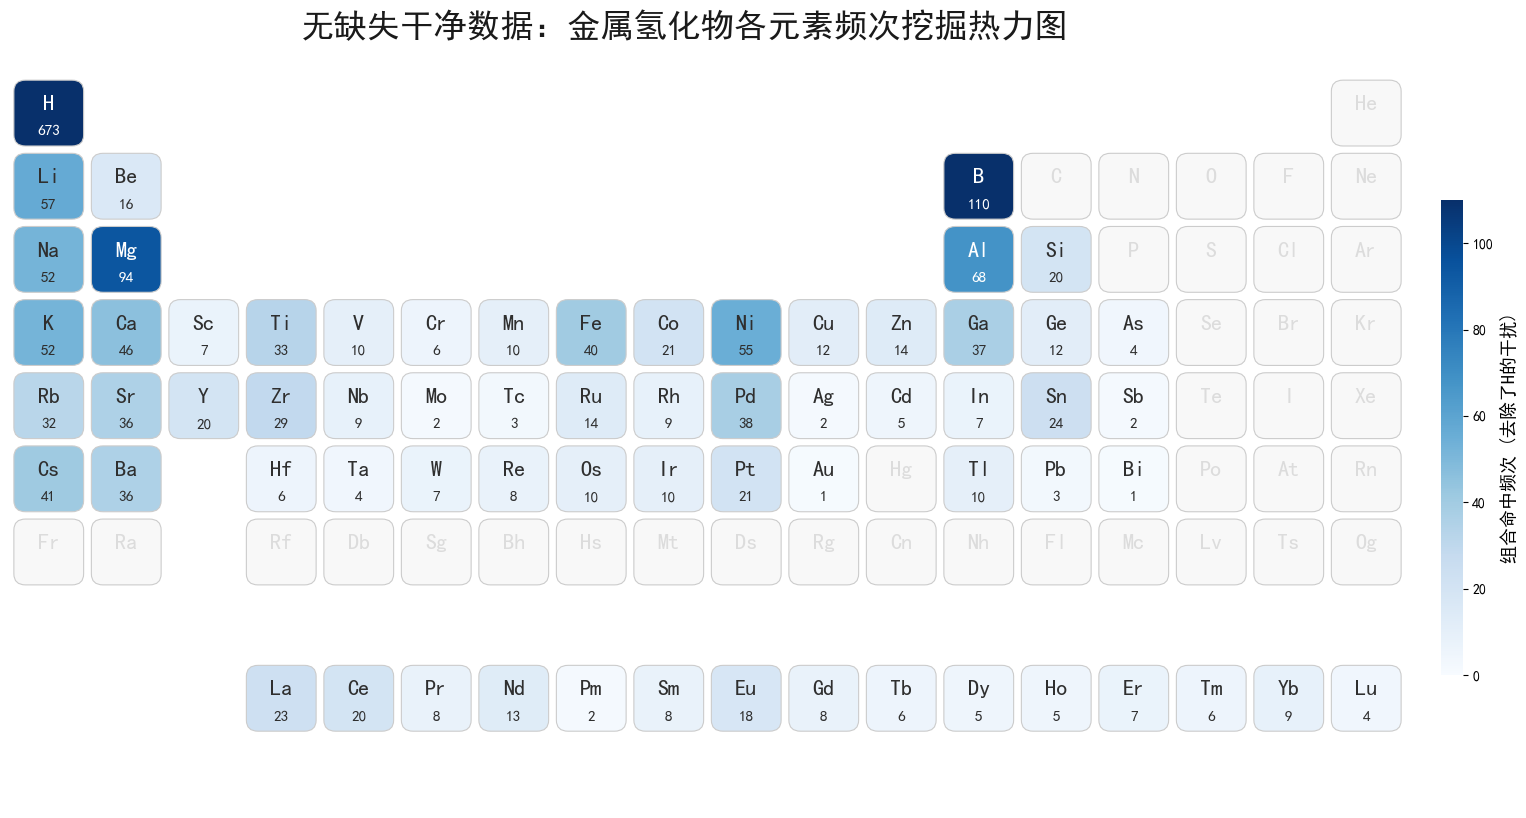


✅ 第一步底层增强数据提取完毕！已落地为本地文件 `step1_enhanced_clean_data.csv`。

 📊 当前阶段构建提取的核心特征维度总览 (含中英对照)
 - Material ID                    : 材料唯一标识符
 - Formula                        : 化学式
 - Formation Energy (eV/atom)     : 形成能 (核心预测目标变量)
 - Energy Above Hull (eV/atom)    : 距凸包能量 (热力学稳定性关键指标)
 - Crystal System                 : 晶系类型 (空间结构特征，待进行独热编码)
 - Spacegroup                     : 空间群编号 (高维结构对称性指标)
 - Band Gap (eV)                  : 带隙
 - Density (g/cm³)                : 密度
 - Atomic Volume (Å³/atom)        : 原子体积
 - Total Magnetization (μB)       : 总磁化强度
 - Num Elements                   : 材料体系复杂度 (包含的元素种类数量)


In [4]:
import matplotlib.patches as patches
import matplotlib.colors as mcolors
from collections import Counter

print("==========================================")
print(" 🔬 元素周期表挖掘深度偏好热图 (频次)")
print("==========================================")

all_elements_list = []
for formula in df_clean['Formula']:
    elems = re.findall(r'[A-Z][a-z]*', formula)
    all_elements_list.extend(elems)
element_counts = Counter(all_elements_list)

pt_layout = {
    'H':(1,1),'He':(1,18),
    'Li':(2,1),'Be':(2,2),'B':(2,13),'C':(2,14),'N':(2,15),'O':(2,16),'F':(2,17),'Ne':(2,18),
    'Na':(3,1),'Mg':(3,2),'Al':(3,13),'Si':(3,14),'P':(3,15),'S':(3,16),'Cl':(3,17),'Ar':(3,18),
    'K':(4,1),'Ca':(4,2),'Sc':(4,3),'Ti':(4,4),'V':(4,5),'Cr':(4,6),'Mn':(4,7),'Fe':(4,8),'Co':(4,9),'Ni':(4,10),'Cu':(4,11),'Zn':(4,12),'Ga':(4,13),'Ge':(4,14),'As':(4,15),'Se':(4,16),'Br':(4,17),'Kr':(4,18),
    'Rb':(5,1),'Sr':(5,2),'Y':(5,3),'Zr':(5,4),'Nb':(5,5),'Mo':(5,6),'Tc':(5,7),'Ru':(5,8),'Rh':(5,9),'Pd':(5,10),'Ag':(5,11),'Cd':(5,12),'In':(5,13),'Sn':(5,14),'Sb':(5,15),'Te':(5,16),'I':(5,17),'Xe':(5,18),
    'Cs':(6,1),'Ba':(6,2),'Hf':(6,4),'Ta':(6,5),'W':(6,6),'Re':(6,7),'Os':(6,8),'Ir':(6,9),'Pt':(6,10),'Au':(6,11),'Hg':(6,12),'Tl':(6,13),'Pb':(6,14),'Bi':(6,15),'Po':(6,16),'At':(6,17),'Rn':(6,18),
    'Fr':(7,1),'Ra':(7,2),'Rf':(7,4),'Db':(7,5),'Sg':(7,6),'Bh':(7,7),'Hs':(7,8),'Mt':(7,9),'Ds':(7,10),'Rg':(7,11),'Cn':(7,12),'Nh':(7,13),'Fl':(7,14),'Mc':(7,15),'Lv':(7,16),'Ts':(7,17),'Og':(7,18),
    'La':(9,4),'Ce':(9,5),'Pr':(9,6),'Nd':(9,7),'Pm':(9,8),'Sm':(9,9),'Eu':(9,10),'Gd':(9,11),'Tb':(9,12),'Dy':(9,13),'Ho':(9,14),'Er':(9,15),'Tm':(9,16),'Yb':(9,17),'Lu':(9,18)
}

fig, ax = plt.subplots(figsize=(18, 9.5))
ax.set_xlim(0.5, 18.5)
ax.set_ylim(10.5, 0.5)
ax.axis('off')

# 排除基础强泛滥元素氢，以防止拉偏热力界限
non_H_counts = {k: v for k, v in element_counts.items() if k != 'H'}
max_count = max(non_H_counts.values()) if non_H_counts else 1
cmap = plt.cm.Blues
norm = mcolors.Normalize(vmin=0, vmax=max_count)

for el, (row, col) in pt_layout.items():
    count = element_counts.get(el, 0)
    if count > 0:
        c_val = min(count, max_count)
        facecolor = cmap(norm(c_val))
        luminance = 0.299*facecolor[0] + 0.587*facecolor[1] + 0.114*facecolor[2]
        textcolor = 'white' if luminance < 0.6 else '#2f2f2f'
    else:
        facecolor, textcolor = '#f8f8f8', '#dcdcdc'

    box = patches.FancyBboxPatch((col - 0.45, row - 0.45), 0.9, 0.9, boxstyle="round,pad=0.0,rounding_size=0.15", linewidth=0.8, edgecolor='#cccccc', facecolor=facecolor)
    ax.add_patch(box)
    ax.text(col, row - 0.12, el, ha='center', va='center', fontsize=16, fontweight='bold', color=textcolor)
    if count > 0:
        ax.text(col, row + 0.25, str(count), ha='center', va='center', fontsize=11, fontweight='bold', color=textcolor)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cb_ax = fig.add_axes([0.92, 0.25, 0.012, 0.5])
cbar = fig.colorbar(sm, cax=cb_ax)
cbar.set_label('组合命中频次 (去除了H的干扰)', fontsize=13)
cbar.outline.set_visible(False)
plt.suptitle("无缺失干净数据：金属氢化物各元素频次挖掘热力图", fontsize=24, fontweight='bold', color='#1a1a1a', y=0.95)
plt.show()

# 导出以备第二步使用
df_clean.to_csv("step1_enhanced_clean_data.csv", index=False, encoding='utf-8-sig')
print("\n✅ 第一步底层增强数据提取完毕！已落地为本地文件 `step1_enhanced_clean_data.csv`。")
print("\n==========================================")
print(" 📊 当前阶段构建提取的核心特征维度总览 (含中英对照)")
print("==========================================")

feature_dict = {
    "Material ID": "材料唯一标识符",
    "Formula": "化学式",
    "Formation Energy (eV/atom)": "形成能 (核心预测目标变量)",
    "Energy Above Hull (eV/atom)": "距凸包能量 (热力学稳定性关键指标)",
    "Crystal System": "晶系类型 (空间结构特征，待进行独热编码)",
    "Spacegroup": "空间群编号 (高维结构对称性指标)",
    "Band Gap (eV)": "带隙",
    "Density (g/cm³)": "密度",
    "Atomic Volume (Å³/atom)": "原子体积",
    "Total Magnetization (μB)": "总磁化强度",
    "Num Elements": "材料体系复杂度 (包含的元素种类数量)"
}

for col in df_clean.columns:
    desc = feature_dict.get(col, "未知特征")
    print(f" - {col:<30} : {desc}")

# 第二步：融合型特征工程构建与双层图拓扑降维

## 2.1 空间结构特征的独热编码 (One-Hot) 与先验压缩
按照您的思路，晶系 (`Crystal System`) 和 空间群 (`Spacegroup`) 属于分类特征，机 
器无法直接理解。
如果对空间群进行 **独热编码 (One-Hot Encoding)**，最多会瞬间带来 230 多维的极度稀疏矩阵（即维度爆炸）。
因此，本段代码先将这部分独立的“结构分类标签”进行独热爆炸，随后立即挂载一个专属的**PCA (主成分分析)**，把几百维的空旷矩阵强行压平凝聚成 4-6 个浓缩的 **“空间结构嵌入潜变量 (Structural Embeddings)”**。这样既能让机器认知结晶形态，又完美规避了维度灾难。

 🔬 第二步：特征工程先导 (清洗与结构化)
当前原始可用特征概览 (含基础属性): (673, 11)

✨ 当前数据集完美无暇，未发现任何缺失特征。

🗑️ 已删除 Spacegroup 列 (Crystal System 已覆盖晶系信息，避免独热编码维度爆炸)
🗑️ 已删除 Energy Above Hull 列 (与目标变量存在数据泄漏)

🔍 扫描到非数值(分类)特征: ['Crystal System']

[📊 正在绘制 Crystal System 晶系分布靓丽圆环图...]


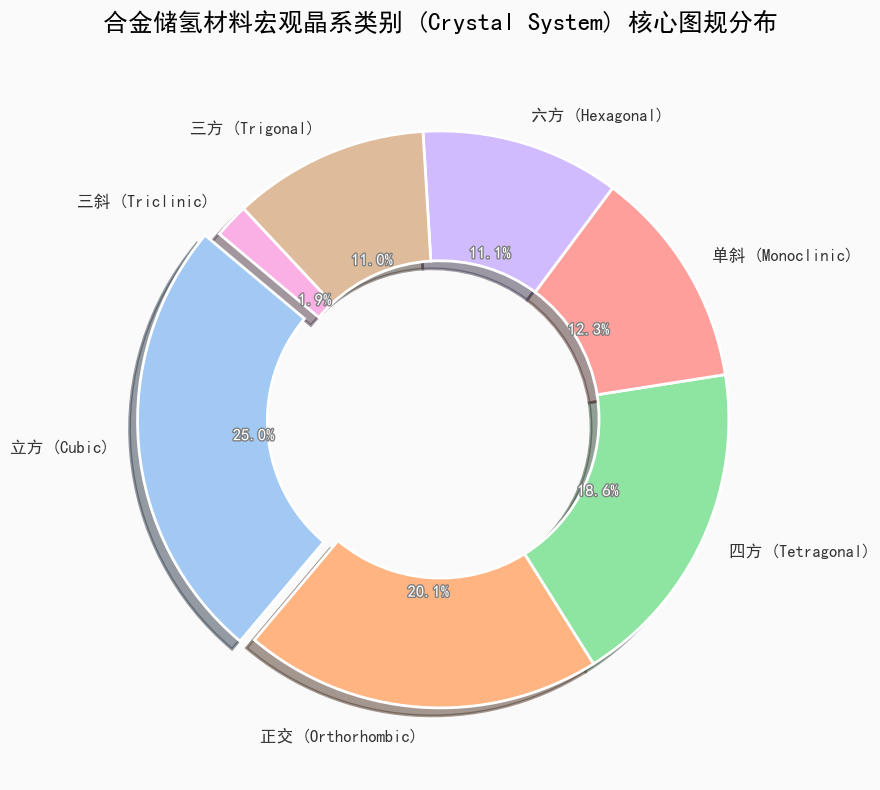


🔧 正在对分类特征进行独热编码(One-Hot Encoding)...
重新编码后数据维度: (673, 15)

✅ 基础特征清洗梳理完成，当前可用于建模的纯净特征合计: 12 个！


In [5]:
print("==========================================")
print(" 🔬 第二步：特征工程先导 (清洗与结构化)")
print("==========================================")
    
df_ml_ready = df_filtered.copy()

print("当前原始可用特征概览 (含基础属性):", df_ml_ready.shape)

# === A. 找出包含缺失值的列及其缺失比例 ===
null_counts_filtered = df_ml_ready.isnull().sum()
null_counts_filtered = null_counts_filtered[null_counts_filtered > 0].sort_values(ascending=False)

if not null_counts_filtered.empty:
    print("\n⚠️ 发现部分特征存在缺失值:")
    print(null_counts_filtered)
    
    # 策略：对于缺失值大于阈值（设为 20%的样本数）的特征，直接丢弃
    threshold = 0.20 * len(df_ml_ready)
    cols_to_drop = null_counts_filtered[null_counts_filtered > threshold].index.tolist()
    
    if cols_to_drop:
        print(f"\n💥 以下特征缺失比例过高 (>20%)，将被直接剔除:\n {cols_to_drop}")
        df_ml_ready = df_ml_ready.drop(columns=cols_to_drop)
        
    df_clean = df_ml_ready.dropna()
    print(f"\n🧹 经过剔除劣质特征及滤除含有残余缺失值的行后，现存样本数: {len(df_clean)} 条")
    df_ml_ready = df_clean.copy()
else:
    print("\n✨ 当前数据集完美无暇，未发现任何缺失特征。")

# 为了彻底解决后续画图时 Å³/atom 和 g/cm³ 在部分设备上显示为空格方格的问题
# 我们在这里直接在底表拦截并替换为安全的英文符号体系
safe_cols = [c.replace('Å³/atom', 'A³/atom').replace('μB', 'uB').replace('A³/atom', 'A^3/atom').replace('g/cm³', 'g/cm^3') for c in df_ml_ready.columns]
df_ml_ready.columns = safe_cols

# === B. 区分数值型与非数值型特征 ===
# 必须保留的标识符列与目标列（修复了大小写与特征集对齐问题，防止字符串变量被误行One-Hot引爆内存）
identifier_cols = ['Material ID', 'Formula']
target_col = 'Formation Energy (eV/atom)'

# [优化修改1] 删除 Spacegroup：Crystal System 已覆盖晶系信息，Spacegroup 独热编码会产生 ~105 个稀疏列导致维度灾难
if 'Spacegroup' in df_ml_ready.columns:
    df_ml_ready = df_ml_ready.drop(columns=['Spacegroup'])
    print("\n🗑️ 已删除 Spacegroup 列 (Crystal System 已覆盖晶系信息，避免独热编码维度爆炸)")

# [优化修改2] 删除 Energy Above Hull：该特征由 DFT 计算得到，本身依赖 Formation Energy (目标变量)，构成数据泄漏
if 'Energy Above Hull (eV/atom)' in df_ml_ready.columns:
    df_ml_ready = df_ml_ready.drop(columns=['Energy Above Hull (eV/atom)'])
    print("🗑️ 已删除 Energy Above Hull 列 (与目标变量存在数据泄漏)")

cat_cols = [col for col in df_ml_ready.columns if df_ml_ready[col].dtype == 'object' and col not in identifier_cols]
print("\n🔍 扫描到非数值(分类)特征:", cat_cols)

# 处理晶系类型结构
if 'Crystal System' in df_ml_ready.columns:
    import matplotlib.pyplot as plt
    import seaborn as sns
    
    # 强制设置安全字体抗方格
    plt.rcParams['font.family'] = 'sans-serif'
    plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial', 'DejaVu Sans']
    plt.rcParams['axes.unicode_minus'] = False
    
    # 晶系体系的中英文优美翻译映射字典
    crystal_mapping = {
        'cubic': '立方 (Cubic)',
        'hex_': '六方 (Hexagonal)',
        'tet': '四方 (Tetragonal)',
        'ortho': '正交 (Orthorhombic)',
        'trig': '三方 (Trigonal)',
        'mono': '单斜 (Monoclinic)',
        'tri': '三斜 (Triclinic)'
    }
    
    print("\n[📊 正在绘制 Crystal System 晶系分布靓丽圆环图...]")
    plt.figure(figsize=(10, 8), facecolor="#FAFAFA")
    crystal_counts = df_ml_ready['Crystal System'].value_counts()
    
    # 替换索引为中文+英文，防范字典内没有的杂项
    labels = [crystal_mapping.get(idx, idx) for idx in crystal_counts.index]
    
    # 提供精美的自然渐变色盘
    colors = sns.color_palette("pastel")[0:len(crystal_counts)]
    
    # 将占比最大的那块稍微"分离"出来 (explode)
    explode = [0.05 if i == 0 else 0 for i in range(len(crystal_counts))]
    
    import matplotlib.patheffects as path_effects
    
    # 变成圆环图 (Donut Chart) 以提升高级感
    wedges, texts, autotexts = plt.pie(
        crystal_counts, labels=labels, autopct='%1.1f%%', 
        colors=colors, startangle=140, explode=explode, shadow=True,
        wedgeprops=dict(width=0.45, edgecolor='w', linewidth=2),
        textprops=dict(color="#333333", fontsize=12, fontweight='bold')
    )
    
    # 调整数字的颜色和样式
    for autotext in autotexts:
        autotext.set_color('white')
        autotext.set_fontsize(12)
        autotext.set_path_effects([path_effects.withStroke(linewidth=2, foreground='gray')])

    plt.title('合金储氢材料宏观晶系类别 (Crystal System) 核心图规分布', fontsize=18, fontweight='bold', pad=20)
    plt.tight_layout()
    plt.show()

# 对于非数值的分类特征，进行独热编码 (One-Hot Encoding)
if cat_cols:
    print("\n🔧 正在对分类特征进行独热编码(One-Hot Encoding)...")
    df_ml_ready = pd.get_dummies(df_ml_ready, columns=cat_cols, drop_first=False)
    print("重新编码后数据维度:", df_ml_ready.shape)

base_cols = [col for col in df_ml_ready.columns if col not in identifier_cols + [target_col]]
print(f"\n✅ 基础特征清洗梳理完成，当前可用于建模的纯净特征合计: {len(base_cols)} 个！")

## 2.2 Magpie 标准化组分特征工程 + 储氢专属补充特征
本步骤使用材料信息学领域广泛验证的 **Magpie (Materials-Agnostic Platform for Informatics and Exploration)** 特征体系，
通过 `matminer` 库的 `ElementProperty.from_preset("magpie")` 自动生成 **132 维**标准化组分特征。

Magpie 对 22 种元素属性（电负性、原子半径、价电子、熔点、共价半径等）分别计算 6 种统计量（mean, std, min, max, range, mode），
覆盖范围远超手工加权特征。

此外，我们额外补充两个储氢领域专属特征：
- **氢质量分数 (Hydrogen Mass Fraction)**：材料中氢的质量占比
- **氢/金属原子比 (H/M Ratio)**：氢原子数与非氢原子数的比值

In [6]:
from pymatgen.core import Composition
from matminer.featurizers.composition import ElementProperty

print("==========================================")
print(" 🧬 阶段B：Magpie 标准化组分特征工程")
print("==========================================")

# === 1. Magpie 132 维自动特征生成 ===
print("🔄 正在使用 matminer Magpie 预设生成 132 维组分特征...")

magpie_featurizer = ElementProperty.from_preset("magpie")

df_magpie_input = df_clean[['Formula']].copy()
df_magpie_input['composition'] = df_magpie_input['Formula'].apply(Composition)

df_magpie_features = magpie_featurizer.featurize_dataframe(
    df_magpie_input, col_id='composition', ignore_errors=True
)
df_magpie_features = df_magpie_features.drop(columns=['Formula', 'composition'])

print(f"✅ Magpie 特征生成完毕！共 {df_magpie_features.shape[1]} 维特征。")

# === 2. 储氢专属补充特征 ===
print("🔄 正在计算储氢专属补充特征 (氢质量分数 + H/M 原子比)...")

def build_hydrogen_features(formula):
    comp = Composition(formula)
    nH = sum(ni for el, ni in comp.items() if el.symbol == 'H')
    mass_H = nH * 1.008
    total_mass = sum(ni * float(el.atomic_mass) for el, ni in comp.items())
    W_H2 = mass_H / total_mass if total_mass > 0 else 0.0

    sum_ni_metal = sum(ni for el, ni in comp.items() if el.symbol != 'H')
    H_Metal_Ratio = nH / sum_ni_metal if sum_ni_metal > 0 else 0.0

    return pd.Series({
        'Hydrogen_Mass_Fraction': W_H2,
        'H_Metal_Ratio': H_Metal_Ratio
    })

df_h_features = df_clean['Formula'].apply(build_hydrogen_features)

# === 3. 合并 Magpie + 储氢补充特征 ===
df_manual_features = pd.concat([df_magpie_features, df_h_features], axis=1)

# 处理可能的 NaN（某些元素 Magpie 属性缺失）
nan_cols = df_manual_features.columns[df_manual_features.isnull().any()].tolist()
if nan_cols:
    print(f"⚠️ 发现 {len(nan_cols)} 列含 NaN，使用列均值填充: {nan_cols[:5]}...")
    df_manual_features = df_manual_features.fillna(df_manual_features.mean())

print(f"\n✅ 最终特征矩阵: Magpie {df_magpie_features.shape[1]} 维 + 储氢补充 2 维 = 共 {df_manual_features.shape[1]} 维")
display(df_manual_features.head())

 🧬 阶段B：Magpie 标准化组分特征工程
🔄 正在使用 matminer Magpie 预设生成 132 维组分特征...


ElementProperty:   0%|          | 0/673 [00:00<?, ?it/s]

✅ Magpie 特征生成完毕！共 132 维特征。
🔄 正在计算储氢专属补充特征 (氢质量分数 + H/M 原子比)...

✅ 最终特征矩阵: Magpie 132 维 + 储氢补充 2 维 = 共 134 维


,MagpieData minimum Number,MagpieData maximum Number,MagpieData range Number,MagpieData mean Number,MagpieData avg_dev Number,MagpieData mode Number,MagpieData minimum MendeleevNumber,MagpieData maximum MendeleevNumber,MagpieData range MendeleevNumber,MagpieData mean MendeleevNumber,...,MagpieData avg_dev GSmagmom,MagpieData mode GSmagmom,MagpieData minimum SpaceGroupNumber,MagpieData maximum SpaceGroupNumber,MagpieData range SpaceGroupNumber,MagpieData mean SpaceGroupNumber,MagpieData avg_dev SpaceGroupNumber,MagpieData mode SpaceGroupNumber,Hydrogen_Mass_Fraction,H_Metal_Ratio
0,1.0,58.0,57.0,18.600000,15.400000,1.0,15.0,92.0,77.0,69.500000,...,0.285789,0.0,194.0,225.0,31.0,206.400000,14.880000,194.0,0.009999,0.666667
1,1.0,56.0,55.0,19.333333,24.444444,1.0,9.0,92.0,83.0,64.333333,...,0.000000,0.0,194.0,229.0,35.0,205.666667,15.555556,194.0,0.014468,2.000000
2,1.0,38.0,37.0,13.333333,16.444444,1.0,8.0,92.0,84.0,64.000000,...,0.000000,0.0,194.0,225.0,31.0,204.333333,13.777778,194.0,0.022491,2.000000
3,1.0,20.0,19.0,7.333333,8.444444,1.0,7.0,92.0,85.0,63.666667,...,0.000000,0.0,194.0,225.0,31.0,204.333333,13.777778,194.0,0.047893,2.000000
4,1.0,13.0,12.0,2.800000,2.160000,1.0,1.0,92.0,91.0,62.800000,...,0.000000,0.0,194.0,229.0,35.0,207.600000,16.320000,194.0,0.112307,1.500000


## 2.3 单步 Spearman 剪枝 + PCA 主成分分析 (v8 简化版)
将 Magpie 生成的 134 维特征与基础物理特征（密度、带隙等）合并后，
利用 **单步斯皮尔曼秩相关剪枝 (阈值 0.75)**，一次性消灭高度冗余的特征对。

v8 核心设计理念：**回归简洁，拒绝过度工程**。
- 删除了 v6/v7 中的三级漏斗 (MI 过滤 + SHAP 反向消除 + 安全网 Spearman)
- 删除了 Crystal System 独热编码 (7 个稀疏列弊大于利)
- 仅保留一步 Spearman 0.80 (与 jupyter-1 Magpie_Base 一致)
- 预期 139 维 → 45-55 维，样本/特征比 ≈ 12-15:1

最后进行 **PCA 主成分分析**（仅可视化），展示特征空间的方差结构。

 🔬 第二步(续)：特征拼接 → 单步 Spearman 0.75 剪枝 → PCA (v8 简化版)
📦 物理强化特征列已拼接合并！当前总维度: (673, 149)
🗑️ 已删除 7 个 Crystal System 独热编码列: ['Crystal System_cubic', 'Crystal System_hex_', 'Crystal System_mono', 'Crystal System_ortho', 'Crystal System_tet', 'Crystal System_tri', 'Crystal System_trig']

剪枝前特征概览:
  总特征数: 139
  样本数: 673
  样本/特征比: 4.8:1

[🧬 单步 Spearman 冗余剪枝 | 阈值=0.80 | 共 139 个候选特征]
 ✂️ 冗余对决: [MagpieData range Number] VS [MagpieData maximum Number] -> 剔除 [MagpieData range Number]
 ✂️ 冗余对决: [MagpieData mean Number] VS [Density (g/cm^3)] -> 剔除 [Density (g/cm^3)]
 ✂️ 冗余对决: [MagpieData avg_dev Number] VS [MagpieData maximum Number] -> 剔除 [MagpieData maximum Number]
 ✂️ 冗余对决: [MagpieData avg_dev Number] VS [MagpieData mean Number] -> 剔除 [MagpieData mean Number]
 ✂️ 冗余对决: [MagpieData range MendeleevNumber] VS [MagpieData minimum MendeleevNumber] -> 剔除 [MagpieData range MendeleevNumber]
 ✂️ 冗余对决: [MagpieData maximum AtomicWeight] VS [MagpieData avg_dev Number] -> 剔除 [MagpieData maximum AtomicWeight]
 ✂️

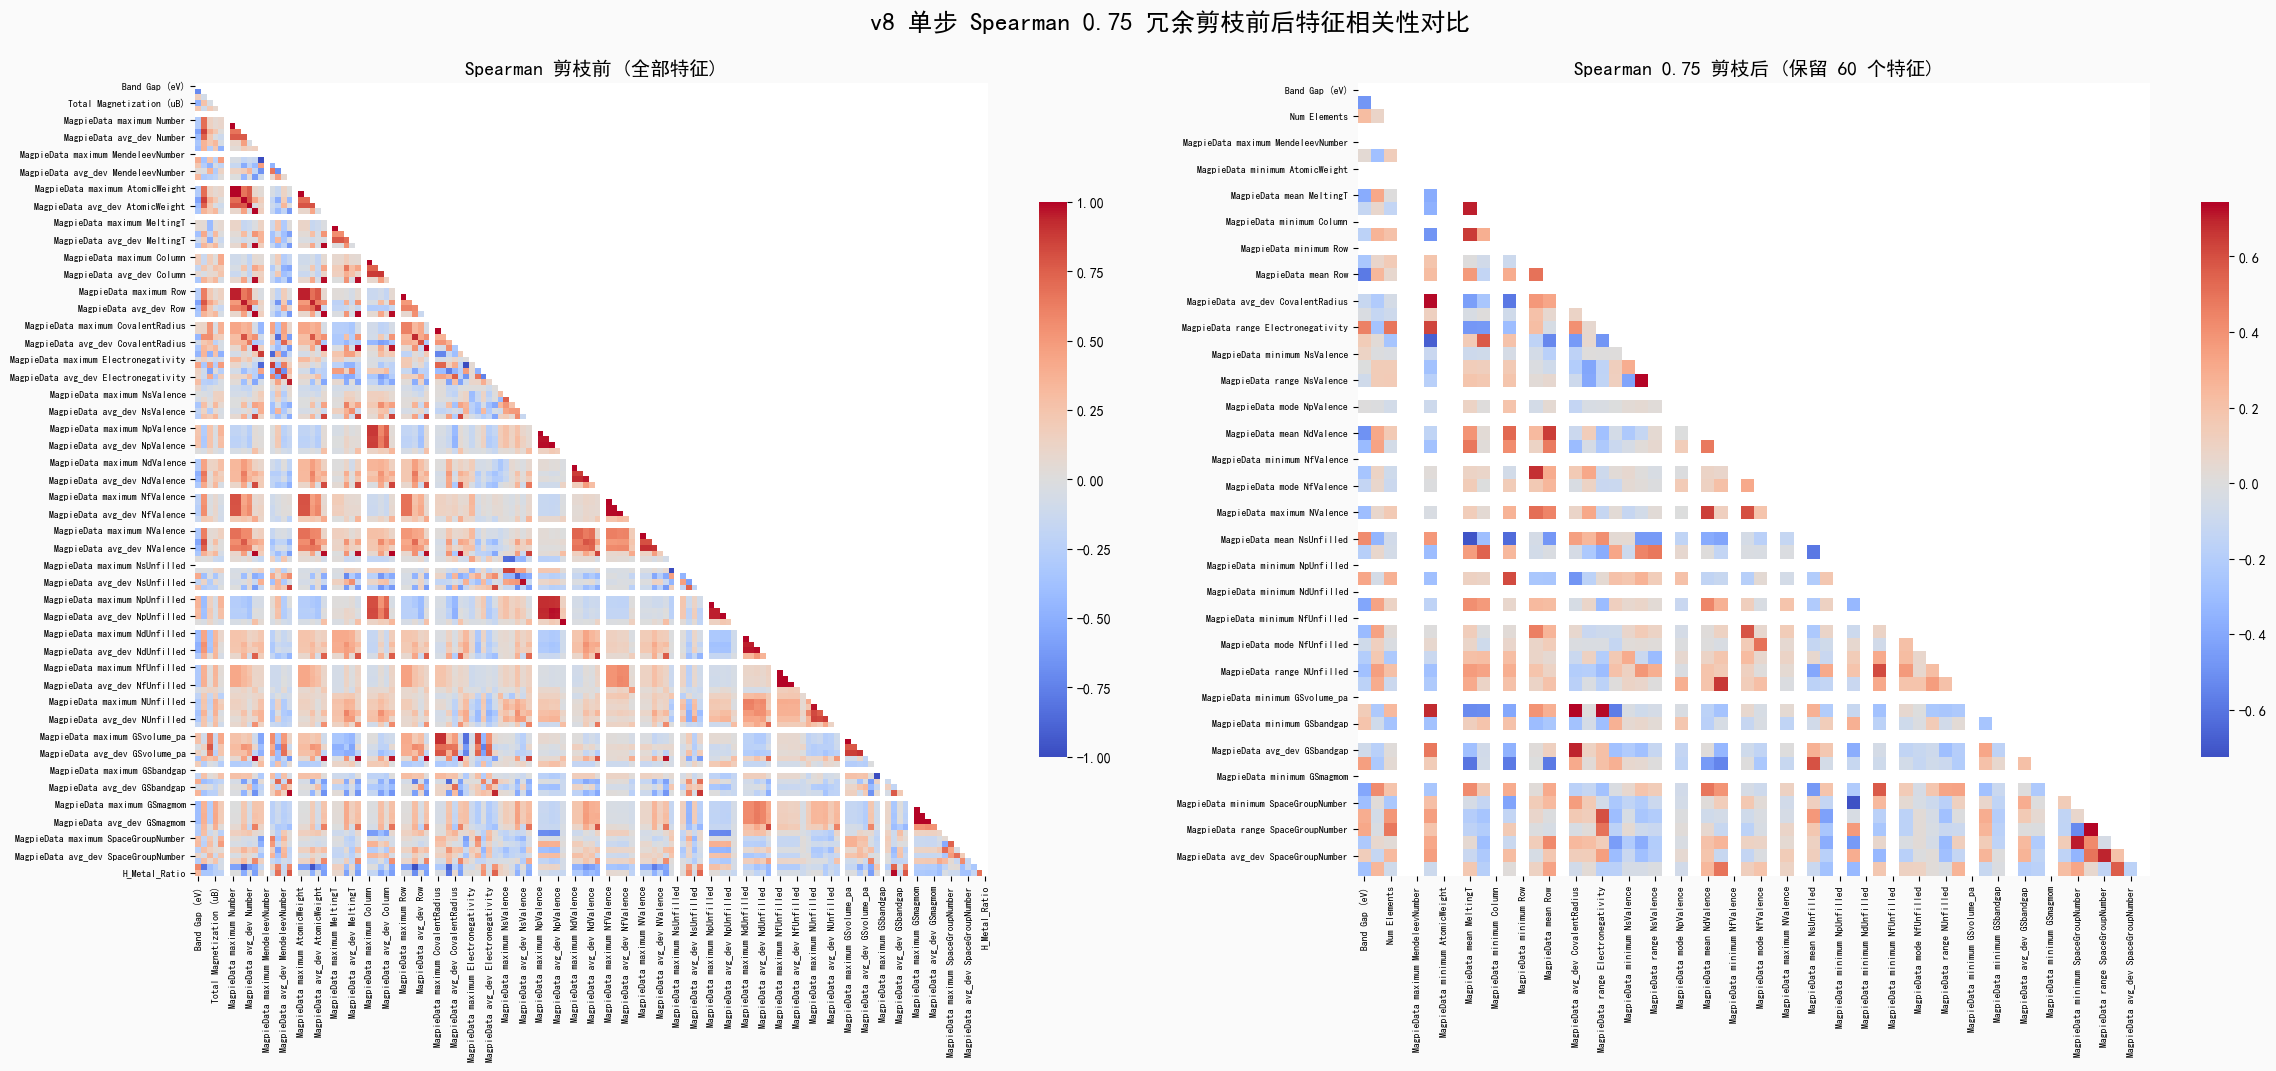


 ✅ v8 特征降维完毕！
  原始特征数: 139 → 剪枝后: 60
  样本/特征比: 673/60 = 11.2:1

[📊 PCA 主成分方差贡献率分析 (仅可视化参考)]


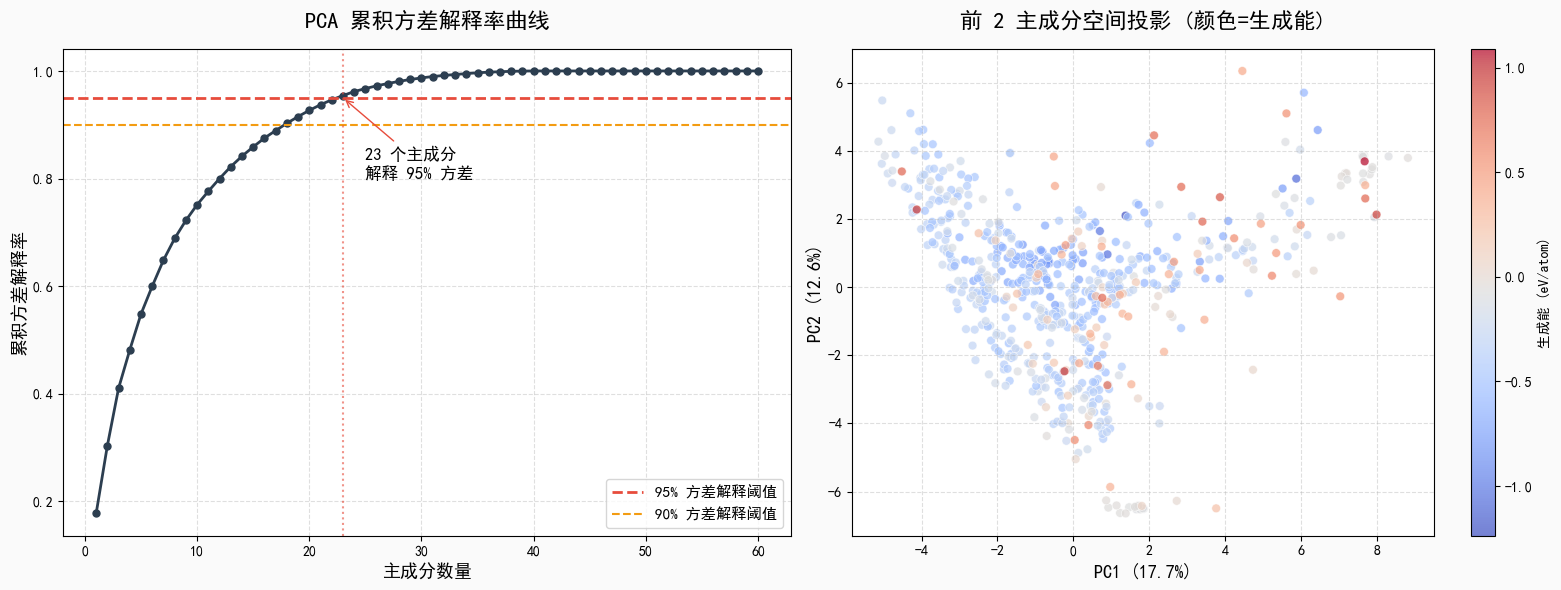


📌 PCA 分析结论: 23 个主成分可解释 95% 的总方差 (共 60 个特征)

[📊 正在绘制生成能理论极值核密度分布...]


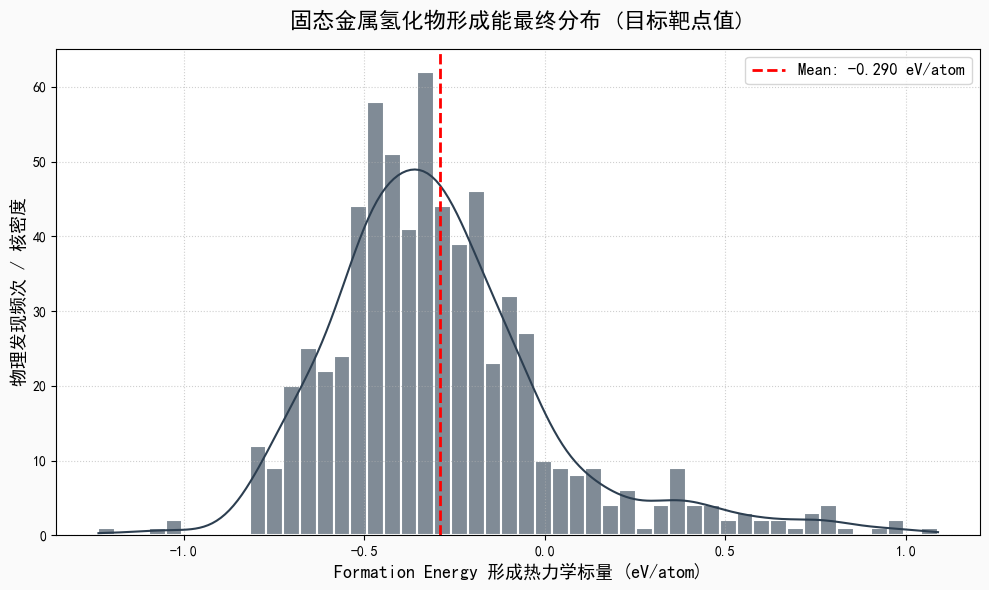


🚀 第二步全面物理特征萃取完毕!


In [7]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'PingFang SC', 'Arial', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

print("==========================================")
print(" 🔬 第二步(续)：特征拼接 → 单步 Spearman 0.75 剪枝 → PCA (v8 简化版)")
print("==========================================")

# 将上一阶段计算的 Magpie + 储氢补充特征拼接到主表
if 'Hydrogen_Mass_Fraction' not in df_ml_ready.columns:
    df_ml_ready = pd.concat([df_ml_ready, df_manual_features], axis=1)
    print(f"📦 物理强化特征列已拼接合并！当前总维度: {df_ml_ready.shape}")

# 统一替换特殊符号防止渲染问题
safe_rename = {c: c.replace('Å³/atom', 'A^3/atom').replace('A³/atom', 'A^3/atom').replace('g/cm³', 'g/cm^3').replace('μB', 'uB') for c in df_ml_ready.columns}
df_ml_ready = df_ml_ready.rename(columns=safe_rename)

# v8 核心：删除 Crystal System 独热编码列（7个稀疏列弊大于利）
crystal_cols = [c for c in df_ml_ready.columns if c.startswith('Crystal System_')]
if crystal_cols:
    df_ml_ready = df_ml_ready.drop(columns=crystal_cols)
    print(f"🗑️ 已删除 {len(crystal_cols)} 个 Crystal System 独热编码列: {crystal_cols}")

# ====== 单步 Spearman 0.80 剪枝 ======
target_col = 'Formation Energy (eV/atom)'
identifier_cols_local = ['Material ID', 'Formula']
feature_cols = [c for c in df_ml_ready.columns
                if c not in identifier_cols_local + [target_col]
                and df_ml_ready[c].dtype.name in ['float64', 'int64', 'float32', 'int32', 'bool', 'uint8']]

print(f"\n剪枝前特征概览:")
print(f"  总特征数: {len(feature_cols)}")
print(f"  样本数: {len(df_ml_ready)}")
print(f"  样本/特征比: {len(df_ml_ready)/len(feature_cols):.1f}:1")

# 剪枝前后热力图对比
fig, axes = plt.subplots(1, 2, figsize=(24, 10), facecolor='#FAFAFA')

df_feat_before = df_ml_ready[feature_cols].copy()
corr_before = df_feat_before.corr(method='spearman')
mask_before = np.triu(np.ones_like(corr_before, dtype=bool))
sns.heatmap(corr_before, mask=mask_before, cmap='coolwarm', center=0, annot=False, square=True,
            cbar_kws={'shrink':0.7}, ax=axes[0])
axes[0].set_title('Spearman 剪枝前 (全部特征)', fontsize=14, fontweight='bold')
axes[0].tick_params(axis='both', labelsize=7)

print(f"\n[🧬 单步 Spearman 冗余剪枝 | 阈值=0.80 | 共 {len(feature_cols)} 个候选特征]")

corr_all = df_feat_before.corr(method='spearman')
target_corr = df_ml_ready[feature_cols + [target_col]].corr(method='spearman')[target_col].abs()
upper_tri = corr_all.abs().where(np.triu(np.ones(corr_all.shape), k=1).astype(bool))
threshold = 0.75
to_drop = set()
for col in upper_tri.columns:
    highly_correlated = upper_tri.index[upper_tri[col] > threshold].tolist()
    for matched_col in highly_correlated:
        if matched_col in to_drop or col in to_drop:
            continue
        corr_col = target_corr.get(col, 0)
        corr_matched = target_corr.get(matched_col, 0)
        if corr_col > corr_matched:
            to_drop.add(matched_col)
            print(f' ✂️ 冗余对决: [{col}] VS [{matched_col}] -> 剔除 [{matched_col}]')
        else:
            to_drop.add(col)
            print(f' ✂️ 冗余对决: [{col}] VS [{matched_col}] -> 剔除 [{col}]')

if to_drop:
    print(f'\n✅ Spearman 0.75 剪枝完毕，共剔除 {len(to_drop)} 个冗余特征。')
    df_ml_ready = df_ml_ready.drop(columns=list(to_drop))
else:
    print("✅ 无高冗余特征对，全部保留。")

# 更新特征列表
feature_cols_after = [c for c in df_ml_ready.columns
                      if c not in identifier_cols_local + [target_col]
                      and df_ml_ready[c].dtype.name in ['float64', 'int64', 'float32', 'int32', 'bool', 'uint8']]

# 记录最终特征列表供后续 cell 使用
FINAL_FEATURE_COLS = feature_cols_after.copy()

# 剪枝后热力图
df_feat_after = df_ml_ready[feature_cols_after].copy()
corr_after = df_feat_after.corr(method='spearman')
mask_after = np.triu(np.ones_like(corr_after, dtype=bool))
sns.heatmap(corr_after, mask=mask_after, cmap='coolwarm', center=0, annot=False, square=True,
            cbar_kws={'shrink':0.7}, ax=axes[1])
axes[1].set_title(f'Spearman 0.75 剪枝后 (保留 {len(feature_cols_after)} 个特征)', fontsize=14, fontweight='bold')
axes[1].tick_params(axis='both', labelsize=7)

plt.suptitle('v8 单步 Spearman 0.75 冗余剪枝前后特征相关性对比', fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print(f"\n==========================================")
print(f" ✅ v8 特征降维完毕！")
print(f"  原始特征数: {len(feature_cols)} → 剪枝后: {len(feature_cols_after)}")
print(f"  样本/特征比: {len(df_ml_ready)}/{len(feature_cols_after)} = {len(df_ml_ready)/len(feature_cols_after):.1f}:1")
print(f"==========================================")

# ====== PCA 方差贡献率分析 (仅可视化) ======
print("\n[📊 PCA 主成分方差贡献率分析 (仅可视化参考)]")

from sklearn.preprocessing import StandardScaler as SS_temp
X_pca = SS_temp().fit_transform(df_ml_ready[feature_cols_after].fillna(0))
pca_full = PCA().fit(X_pca)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), facecolor='#FAFAFA')

cumvar = np.cumsum(pca_full.explained_variance_ratio_)
axes[0].plot(range(1, len(cumvar)+1), cumvar, 'o-', color='#2c3e50', linewidth=2, markersize=5)
axes[0].axhline(y=0.95, color='#e74c3c', linestyle='--', linewidth=2, label='95% 方差解释阈值')
axes[0].axhline(y=0.90, color='#f39c12', linestyle='--', linewidth=1.5, label='90% 方差解释阈值')
n_95 = int(np.argmax(cumvar >= 0.95) + 1)
axes[0].axvline(x=n_95, color='#e74c3c', linestyle=':', alpha=0.6)
axes[0].annotate(f'{n_95} 个主成分\n解释 95% 方差', xy=(n_95, 0.95), xytext=(n_95+2, 0.80),
                fontsize=12, arrowprops=dict(arrowstyle='->', color='#e74c3c'))
axes[0].set_title('PCA 累积方差解释率曲线', fontsize=16, fontweight='bold', pad=15)
axes[0].set_xlabel('主成分数量', fontsize=13)
axes[0].set_ylabel('累积方差解释率', fontsize=13)
axes[0].legend(fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.4)

pca_2d = PCA(n_components=2).fit_transform(X_pca)
sc = axes[1].scatter(pca_2d[:, 0], pca_2d[:, 1],
                     c=df_ml_ready[target_col], cmap='coolwarm',
                     alpha=0.7, s=40, edgecolors='white', linewidths=0.5)
plt.colorbar(sc, ax=axes[1], label='生成能 (eV/atom)')
axes[1].set_title('前 2 主成分空间投影 (颜色=生成能)', fontsize=16, fontweight='bold', pad=15)
axes[1].set_xlabel(f'PC1 ({pca_full.explained_variance_ratio_[0]*100:.1f}%)', fontsize=13)
axes[1].set_ylabel(f'PC2 ({pca_full.explained_variance_ratio_[1]*100:.1f}%)', fontsize=13)
axes[1].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

print(f"\n📌 PCA 分析结论: {n_95} 个主成分可解释 95% 的总方差 (共 {len(feature_cols_after)} 个特征)")

# === 生成能目标密度分布 ===
print("\n[📊 正在绘制生成能理论极值核密度分布...]")
plt.figure(figsize=(10, 6), facecolor="#FAFAFA")

target_data = df_ml_ready[target_col]
if not target_data.empty:
    sns.histplot(target_data, kde=True, bins=50, color='#2c3e50', alpha=0.6, edgecolor="white", linewidth=1.5)
    plt.axvline(target_data.mean(), color='r', linestyle='dashed', linewidth=2, label=f'Mean: {target_data.mean():.3f} eV/atom')
    plt.title('固态金属氢化物形成能最终分布 (目标靶点值)', fontsize=16, fontweight='bold', pad=15)
    plt.xlabel('Formation Energy 形成热力学标量 (eV/atom)', fontsize=13)
    plt.ylabel('物理发现频次 / 核密度', fontsize=13)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend(fontsize=12)
    plt.tight_layout()
    plt.show()

df_ml_ready.to_csv("step2_reduced_ml_data.csv", index=False, encoding='utf-8-sig')
print("\n🚀 第二步全面物理特征萃取完毕!")

 📊 终极盘点：最终入模特征群的斯皮尔曼相关性热图


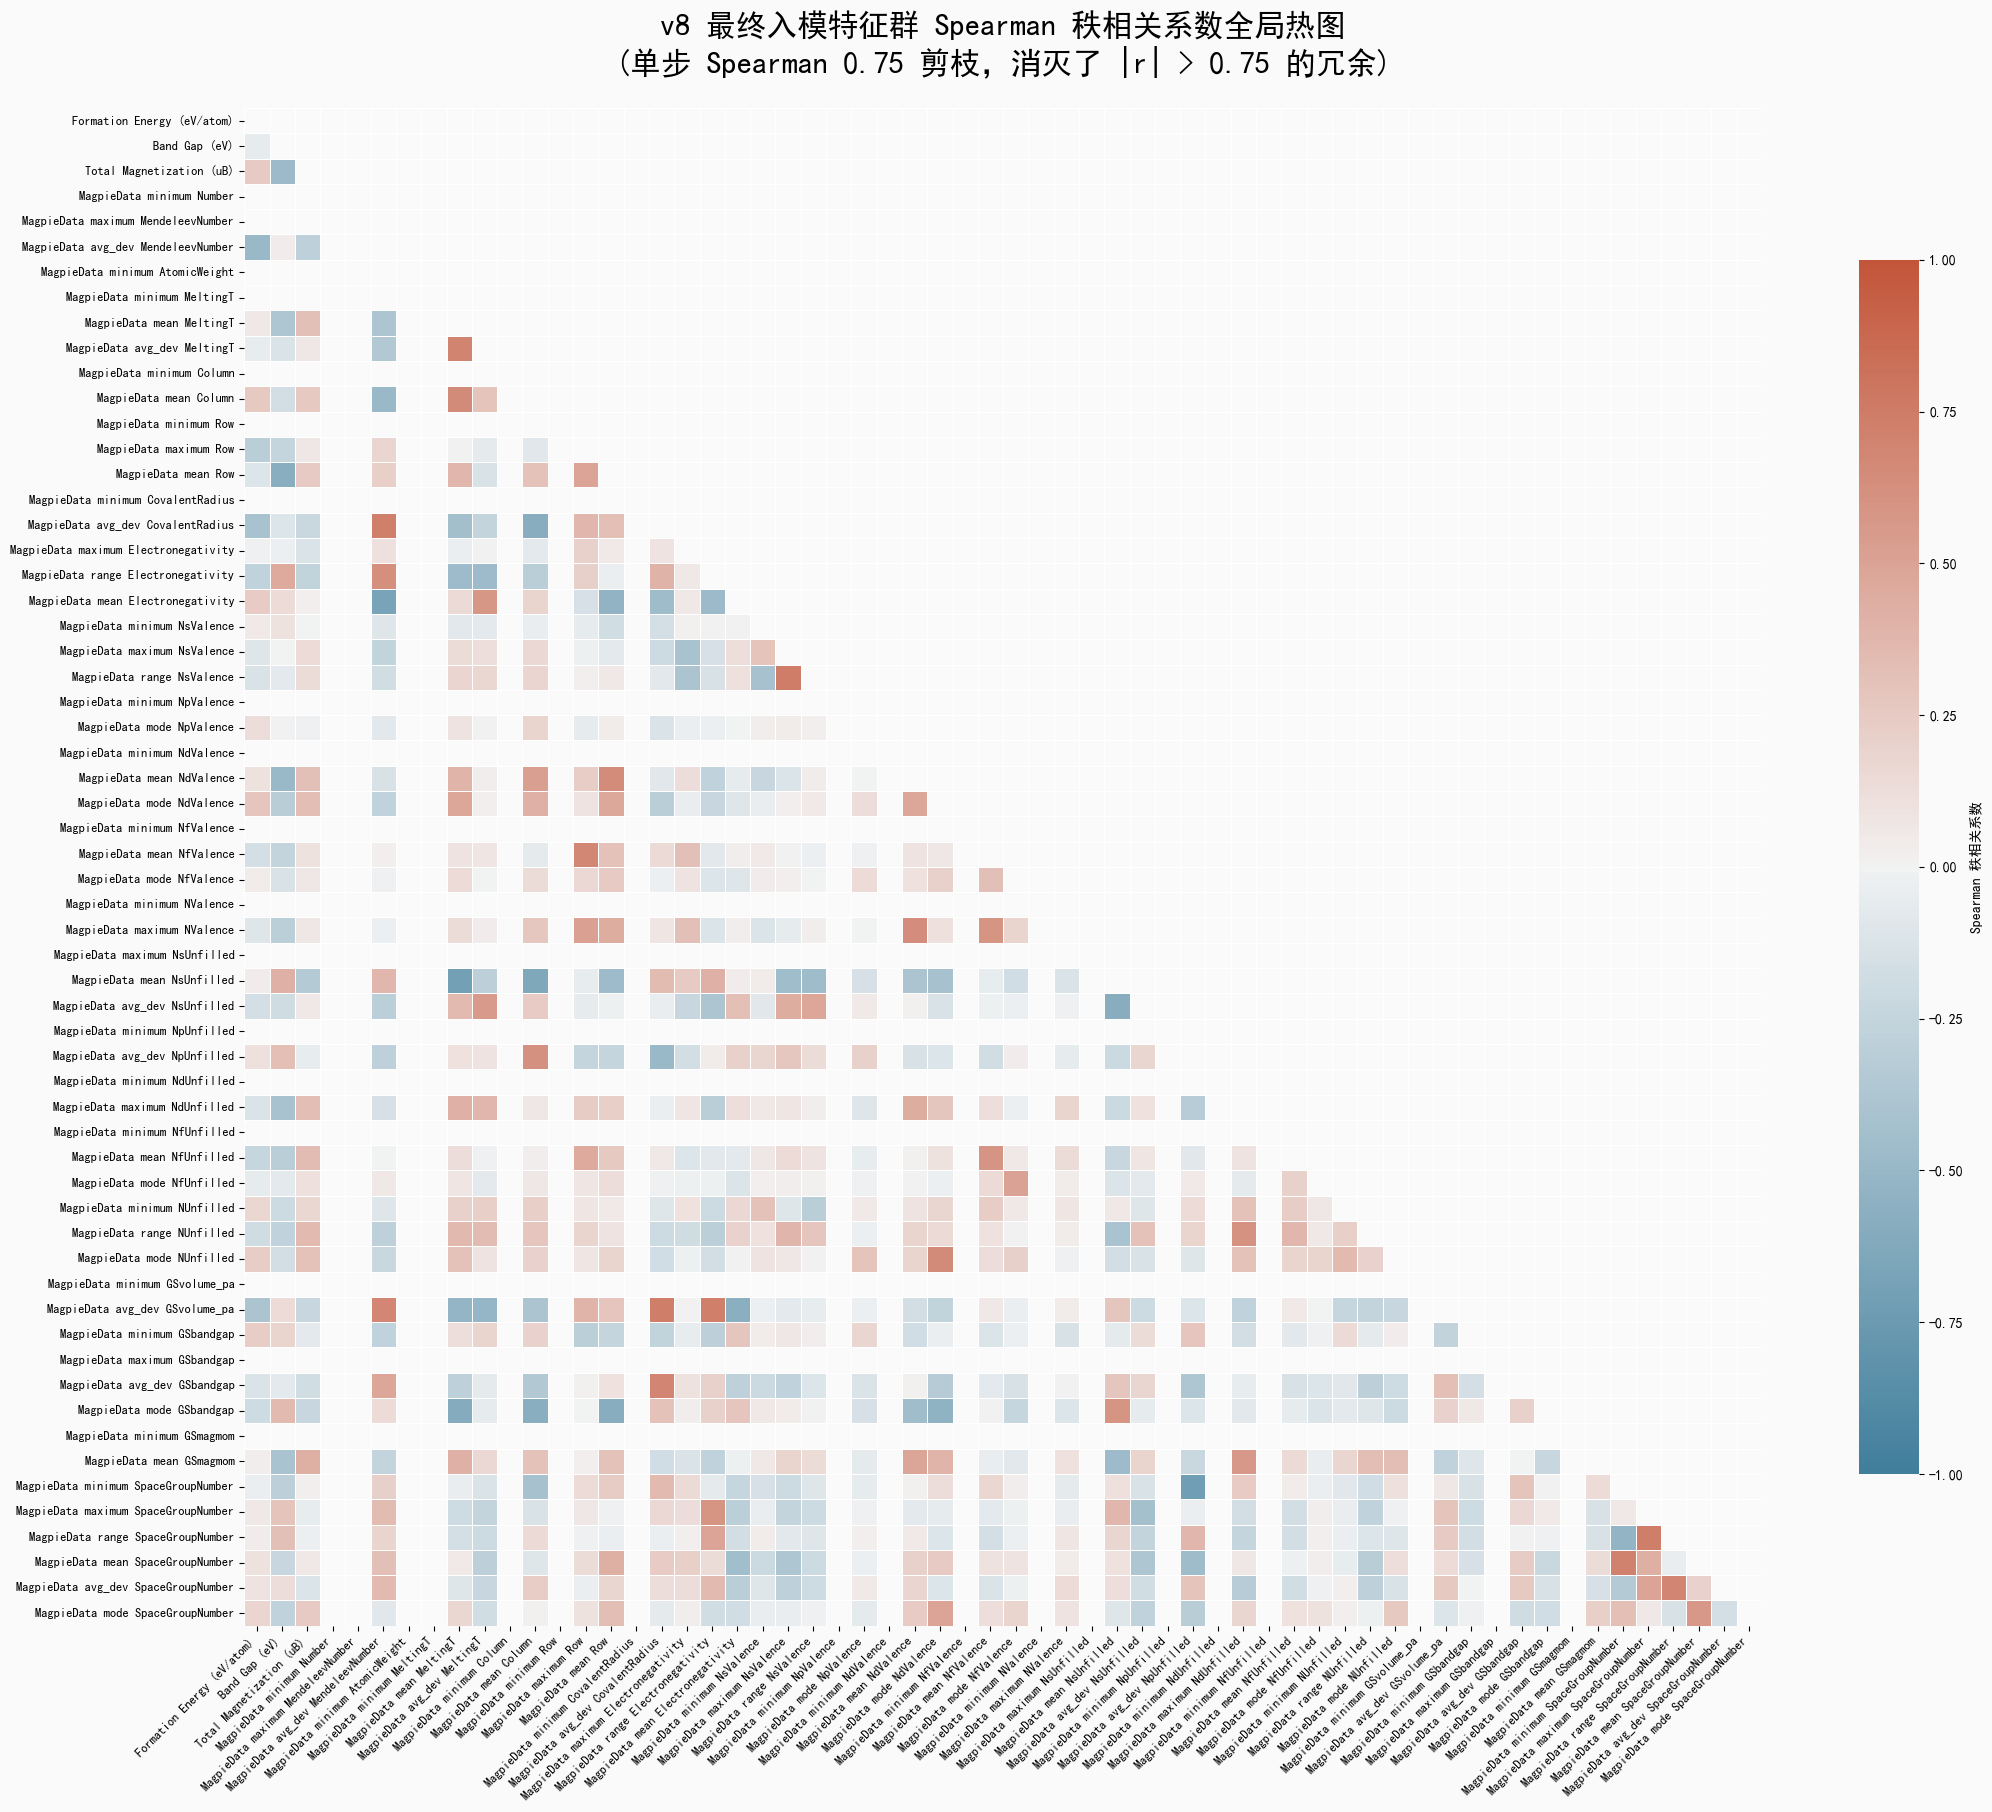


 🎯 最终确认：将进入后续模型训练的纯净特征清单 (共 60 维模型特征)
  1. Formation Energy (eV/atom)
  2. Band Gap (eV)
  3. Total Magnetization (uB)
  4. MagpieData minimum Number
  5. MagpieData maximum MendeleevNumber
  6. MagpieData avg_dev MendeleevNumber
  7. MagpieData minimum AtomicWeight
  8. MagpieData minimum MeltingT
  9. MagpieData mean MeltingT
 10. MagpieData avg_dev MeltingT
 11. MagpieData minimum Column
 12. MagpieData mean Column
 13. MagpieData minimum Row
 14. MagpieData maximum Row
 15. MagpieData mean Row
 16. MagpieData minimum CovalentRadius
 17. MagpieData avg_dev CovalentRadius
 18. MagpieData maximum Electronegativity
 19. MagpieData range Electronegativity
 20. MagpieData mean Electronegativity
 21. MagpieData minimum NsValence
 22. MagpieData maximum NsValence
 23. MagpieData range NsValence
 24. MagpieData minimum NpValence
 25. MagpieData mode NpValence
 26. MagpieData minimum NdValence
 27. MagpieData mean NdValence
 28. MagpieData mode NdValence
 29. MagpieData minimum NfValence
 3

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

print("==========================================")
print(" 📊 终极盘点：最终入模特征群的斯皮尔曼相关性热图")
print("==========================================")

heatmap_cols = [c for c in df_ml_ready.columns if c not in ['Material ID', 'Formula', 'Num Elements']]
df_heatmap = df_ml_ready[heatmap_cols].copy()

safe_cols = [c.replace('Å³/atom', 'A^3/atom').replace('A³/atom', 'A^3/atom').replace('μB', 'uB').replace('g/cm³', 'g/cm^3') for c in df_heatmap.columns]
df_heatmap.columns = safe_cols

corr_matrix = df_heatmap.corr(method='spearman')
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(22, 18), facecolor='#FAFAFA')
cmap = sns.diverging_palette(230, 20, as_cmap=True, center='light')

annot_flag = len(corr_matrix) <= 25
sns.heatmap(corr_matrix, mask=mask, cmap=cmap, vmin=-1, vmax=1, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .8, "label": "Spearman 秩相关系数"},
            annot=annot_flag, fmt=".2f" if annot_flag else "",
            annot_kws={"size": 7, "weight": "bold"} if annot_flag else {})
plt.title('v8 最终入模特征群 Spearman 秩相关系数全局热图\n(单步 Spearman 0.75 剪枝，消灭了 |r| > 0.75 的冗余)',
          fontsize=22, fontweight='bold', pad=25)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)
ax = plt.gca()
ax.set_facecolor('#FAFAFA')
plt.tight_layout()
plt.show()

final_cols = df_ml_ready.columns.tolist()
n_model_features = len(final_cols) - len(["Material ID", "Formula", "Num Elements"])
print("\n==========================================")
print(f' 🎯 最终确认：将进入后续模型训练的纯净特征清单 (共 {n_model_features} 维模型特征)')
print("==========================================")
for idx, col in enumerate(df_heatmap.columns, 1):
    print(f' {idx:2d}. {col}')

# 第三步：强悍数据的切分与防数据泄漏屏障

## 3.1 双向验证集切分与全尺度标准化 (StandardScaler)
在进入模型战壕前，我们需要将极简后留下的特征进行最后一次打磨：
1. **防止数据穿越**：先分离测试集和训练集（80% / 20%），再根据训练集的均值方差去标准化全量数据。绝对不能先标准化再切分！
2. **提取标识**：`Material ID` 和 `Formula` 会被隔离为纯净索引，不参与训练，以便我们最后输出 Top 15 榜单时“有据可查”。

 ⚔️ 阶段D：机器学习防穿透切割与尺度规范化 (v8 简化版)
✅ 数据矩阵阵型排列完毕 (v8 简化版，无 Yeo-Johnson 变换)：
 -> 整体入模维度：60 维特征
 -> 训练集战队：538 条记录
 -> 测试经验厂：135 条盲测记录
 -> 样本/特征比: 9.0:1

 ⚖️ 数据切分无偏性(一致性)分布核验大屏


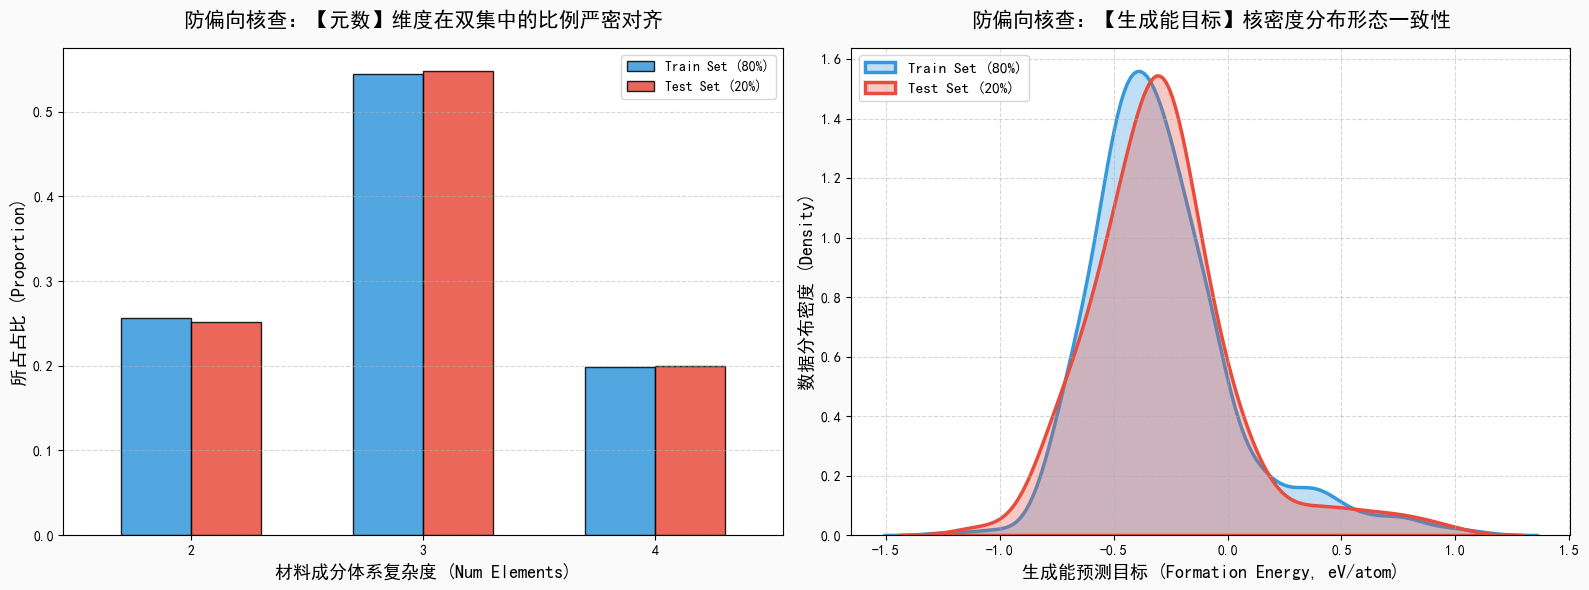

即将进入地狱斗兽场... ...


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

print("==========================================")
print(" ⚔️ 阶段D：机器学习防穿透切割与尺度规范化 (v8 简化版)")
print("==========================================")

# == 重启容错机制 ==
if ('df_ml_ready' not in globals()):
    try:
        df_ml_ready = pd.read_csv("step2_reduced_ml_data.csv")
    except:
        print("❌ 警告：未找到 step2 数据，请确保上一步已跑通。")

# 1. 拆分
identifier_cols = ['Material ID', 'Formula']
target_col = 'Formation Energy (eV/atom)'

# 使用 v8 精选特征列表
if 'FINAL_FEATURE_COLS' in dir():
    X_raw = df_ml_ready[FINAL_FEATURE_COLS].copy()
else:
    cols_to_drop = identifier_cols + [target_col]
    if 'Num Elements' in df_ml_ready.columns:
        cols_to_drop.append('Num Elements')
    X_raw = df_ml_ready.drop(columns=[c for c in cols_to_drop if c in df_ml_ready.columns])

y = df_ml_ready[target_col]
identities = df_ml_ready[identifier_cols]

# 2. 分层抽样
if 'Num Elements' in df_ml_ready.columns:
    temp_hydride_type = df_ml_ready['Num Elements'].astype(int).astype(str) + "元"
else:
    temp_hydride_type = pd.Series(["unknown"] * len(df_ml_ready), index=df_ml_ready.index)

def categorize_energy(e):
    if e < -0.5:
        return "强稳定区(<-0.5)"
    elif e <= 0:
        return "适宜储氢区[-0.5, 0]"
    else:
        return "不稳定区(>0)"

stratify_label = temp_hydride_type + " & " + df_ml_ready[target_col].apply(categorize_energy)

vc = stratify_label.value_counts()
singletons = vc[vc < 2].index
if len(singletons) > 0:
    majority_class = vc.idxmax()
    stratify_label = stratify_label.apply(lambda x: majority_class if x in singletons else x)

# v8: random_state=42 (与 jupyter-1 一致)
X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X_raw, y, identities, test_size=0.20, random_state=42, stratify=stratify_label
)

# 3. StandardScaler (仍然保留独立的 scaler 用于后续全量预测)
scaler_ml = StandardScaler()
X_train_scaled = pd.DataFrame(scaler_ml.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled  = pd.DataFrame(scaler_ml.transform(X_test), columns=X_test.columns, index=X_test.index)

print(f"✅ 数据矩阵阵型排列完毕 (v8 简化版，无 Yeo-Johnson 变换)：")
print(f" -> 整体入模维度：{X_train_scaled.shape[1]} 维特征")
print(f" -> 训练集战队：{X_train_scaled.shape[0]} 条记录")
print(f" -> 测试经验厂：{X_test_scaled.shape[0]} 条盲测记录")
print(f" -> 样本/特征比: {X_train_scaled.shape[0]/X_train_scaled.shape[1]:.1f}:1\n")

print("==========================================")
print(" ⚖️ 数据切分无偏性(一致性)分布核验大屏")
print("==========================================")

fig, axes = plt.subplots(1, 2, figsize=(16, 6), facecolor="#FAFAFA")

if 'Num Elements' in df_ml_ready.columns:
    train_idx = X_train.index
    test_idx = X_test.index
    train_ne = df_ml_ready.loc[train_idx, 'Num Elements']
    test_ne = df_ml_ready.loc[test_idx, 'Num Elements']
    train_counts = train_ne.value_counts(normalize=True).sort_index()
    test_counts = test_ne.value_counts(normalize=True).sort_index()

    df_dist = pd.DataFrame({'Train Set (80%)': train_counts, 'Test Set (20%)': test_counts})
    df_dist.plot(kind='bar', ax=axes[0], color=['#3498db', '#e74c3c'], alpha=0.85, edgecolor='black', width=0.6)
    axes[0].set_title('防偏向核查：【元数】维度在双集中的比例严密对齐', fontsize=15, fontweight='bold', pad=15)
    axes[0].set_xlabel('材料成分体系复杂度 (Num Elements)', fontsize=13)
    axes[0].set_ylabel('所占占比 (Proportion)', fontsize=13)
    axes[0].tick_params(axis='x', rotation=0)
    axes[0].grid(axis='y', linestyle='--', alpha=0.5)

sns.kdeplot(y_train, ax=axes[1], color='#3498db', fill=True, alpha=0.3, label='Train Set (80%)', linewidth=2.5)
sns.kdeplot(y_test, ax=axes[1], color='#e74c3c', fill=True, alpha=0.3, label='Test Set (20%)', linewidth=2.5)
axes[1].set_title('防偏向核查：【生成能目标】核密度分布形态一致性', fontsize=15, fontweight='bold', pad=15)
axes[1].set_xlabel('生成能预测目标 (Formation Energy, eV/atom)', fontsize=13)
axes[1].set_ylabel('数据分布密度 (Density)', fontsize=13)
axes[1].grid(axis='both', linestyle='--', alpha=0.5)
axes[1].legend(loc='upper left', fontsize=11)

plt.tight_layout()
plt.show()

print("即将进入地狱斗兽场... ...")

 🤖 第四步：七大顶尖回归模型角斗场 (v8 Baseline 检验)
🚀 开始七大模型训练与双向(Train/Test)预测评估...

✔️ Ridge (线性基准)                 | Train R²: 0.6368 → Test R²: 0.6059 | Test MSE: 0.0392
✔️ SVR (支持向量机)                  | Train R²: 0.9048 → Test R²: 0.5678 | Test MSE: 0.0430
✔️ Decision Tree (决策树)          | Train R²: 1.0000 → Test R²: 0.4056 | Test MSE: 0.0592
✔️ Random Forest (树集成)          | Train R²: 0.9550 → Test R²: 0.8143 | Test MSE: 0.0185
✔️ XGBoost (极限梯度)               | Train R²: 0.9975 → Test R²: 0.8107 | Test MSE: 0.0189
✔️ LightGBM (轻量梯度)              | Train R²: 0.9690 → Test R²: 0.8071 | Test MSE: 0.0192
✔️ CatBoost (分类梯度)              | Train R²: 0.9312 → Test R²: 0.8131 | Test MSE: 0.0186

 🏆 Baseline 战绩排行榜 (按 Test R2 降序)


,Model,Train R2,Test R2,Train MSE,Test MSE,Train RMSE,Test RMSE,Train MAE,Test MAE
0,Random Forest (树集成),0.955041,0.814255,0.004531,0.018496,0.067310,0.135999,0.038024,0.085594
1,CatBoost (分类梯度),0.931185,0.813065,0.006935,0.018614,0.083274,0.136434,0.061787,0.090742
2,XGBoost (极限梯度),0.997463,0.810686,0.000256,0.018851,0.015988,0.137299,0.011713,0.086031
3,LightGBM (轻量梯度),0.969024,0.807118,0.003122,0.019206,0.055871,0.138587,0.031004,0.093018
4,Ridge (线性基准),0.636801,0.605875,0.036600,0.039245,0.191311,0.198104,0.132916,0.143666
5,SVR (支持向量机),0.904788,0.567773,0.009595,0.043039,0.097952,0.207459,0.073620,0.114787
6,Decision Tree (决策树),1.000000,0.405615,0.000000,0.059186,0.000000,0.243282,0.000000,0.123640



[绘制 Baseline 所有模型的 Parity Plot 矩阵...]


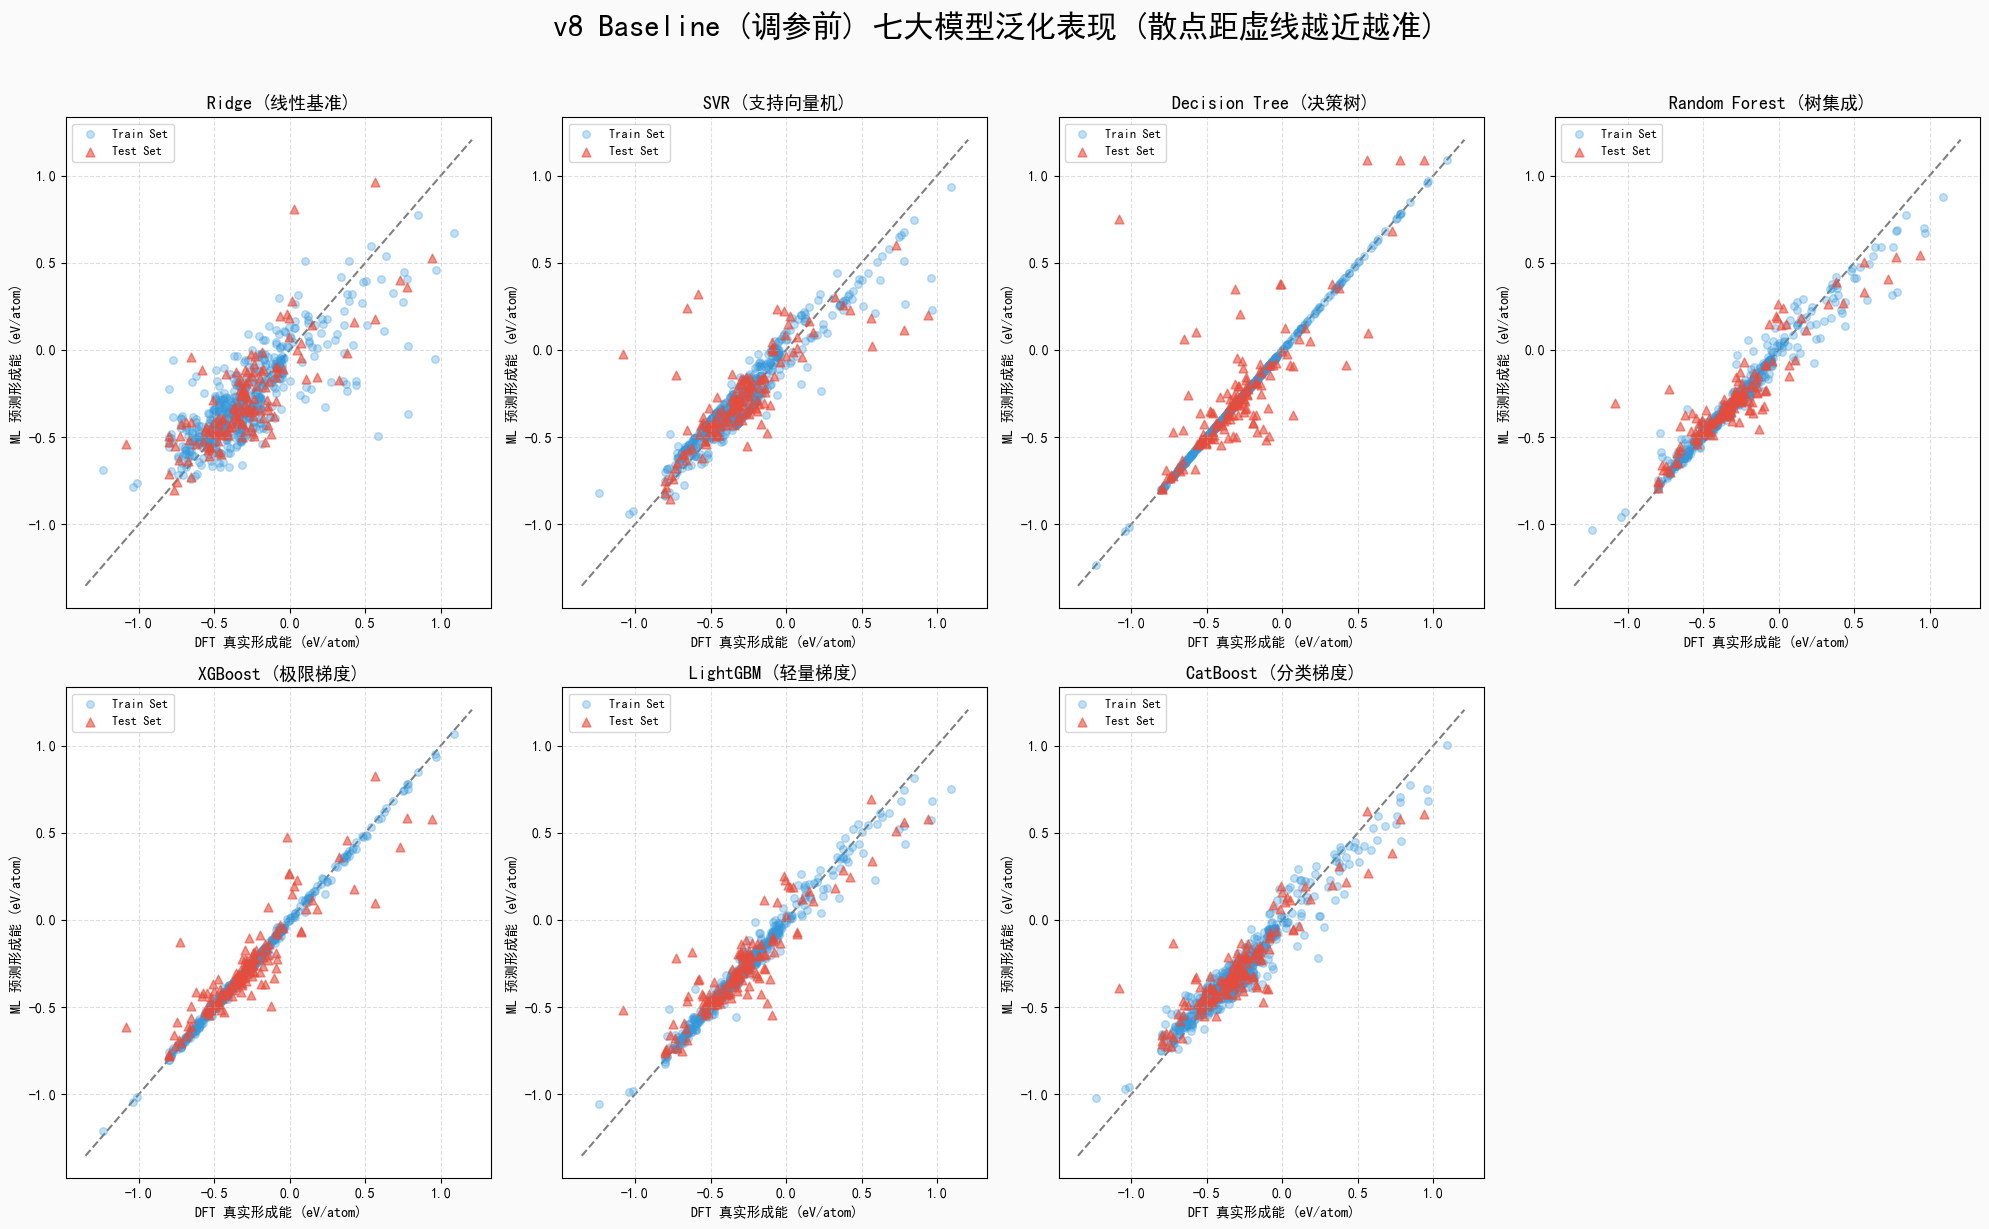


[为 Baseline 最佳模型 Random Forest (树集成) 解析 TOP 15 物理特征...]


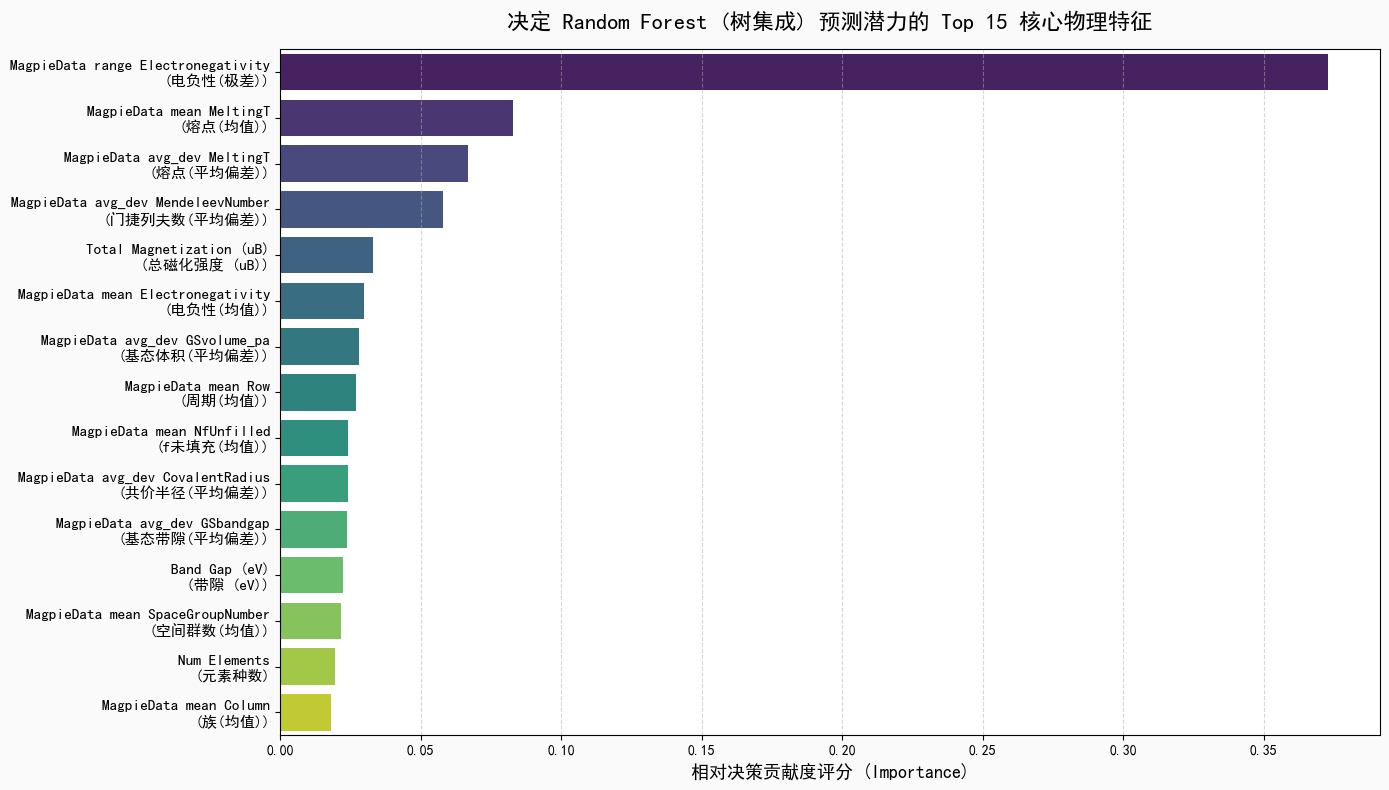

In [10]:
!pip install -q xgboost lightgbm catboost scikit-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.linear_model import Ridge
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostRegressor

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# --- 特征中英文翻译映射字典 ---
feature_cn_dict = {
    "Band Gap (eV)": "带隙 (eV)",
    "Density (g/cm^3)": "密度 (g/cm^3)",
    "Atomic Volume (A^3/atom)": "原子体积 (A^3/atom)",
    "Total Magnetization (uB)": "总磁化强度 (uB)",
    "Num Elements": "元素种数",
    "Hydrogen_Mass_Fraction": "氢质量分数",
    "H_Metal_Ratio": "氢/金属原子比",
}
_magpie_prop_cn = {
    "Number": "原子序数", "MendeleevNumber": "门捷列夫数",
    "AtomicWeight": "原子量", "MeltingT": "熔点",
    "Column": "族", "Row": "周期",
    "CovalentRadius": "共价半径", "Electronegativity": "电负性",
    "NsValence": "s价电子", "NpValence": "p价电子",
    "NdValence": "d价电子", "NfValence": "f价电子",
    "NValence": "总价电子", "NsUnfilled": "s未填充",
    "NpUnfilled": "p未填充", "NdUnfilled": "d未填充",
    "NfUnfilled": "f未填充", "NUnfilled": "总未填充",
    "GSvolume_pa": "基态体积", "GSbandgap": "基态带隙",
    "GSmagmom": "基态磁矩", "SpaceGroupNumber": "空间群数",
}
_magpie_stat_cn = {
    "mean": "均值", "avg_dev": "平均偏差", "minimum": "最小",
    "maximum": "最大", "range": "极差", "mode": "众数",
}
for prop_en, prop_cn in _magpie_prop_cn.items():
    for stat_en, stat_cn in _magpie_stat_cn.items():
        key = f"MagpieData {stat_en} {prop_en}"
        feature_cn_dict[key] = f"{prop_cn}({stat_cn})"
def translate_feat(feat_name):
    feat_name_safe = str(feat_name).replace('Å³/atom', 'A^3/atom').replace('A³/atom', 'A^3/atom')\
                                   .replace('g/cm³', 'g/cm^3').replace('μB', 'uB')
    cn_name = feature_cn_dict.get(feat_name_safe, feat_name_safe)
    if cn_name == feat_name_safe:
        for en, cn in feature_cn_dict.items():
            if en in cn_name:
                cn_name = cn_name.replace(en, cn)
                break
    return cn_name

print("==========================================")
print(" 🤖 第四步：七大顶尖回归模型角斗场 (v8 Baseline 检验)")
print("==========================================")

# 安全列名
X_train_scaled.columns = [c.replace('Å³/atom', 'A^3/atom').replace('A³/atom', 'A^3/atom').replace('g/cm³', 'g/cm^3').replace('μB', 'uB') for c in X_train_scaled.columns]
X_test_scaled.columns = [c.replace('Å³/atom', 'A^3/atom').replace('A³/atom', 'A^3/atom').replace('g/cm³', 'g/cm^3').replace('μB', 'uB') for c in X_test_scaled.columns]

# v8: 7 个模型 (含 Decision Tree)
models = {
    "Ridge (线性基准)": Ridge(alpha=1.0),
    "SVR (支持向量机)": SVR(C=1.0, epsilon=0.1),
    "Decision Tree (决策树)": DecisionTreeRegressor(random_state=42),
    "Random Forest (树集成)": RandomForestRegressor(n_estimators=100, random_state=42),
    "XGBoost (极限梯度)": xgb.XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "LightGBM (轻量梯度)": lgb.LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbose=-1),
    "CatBoost (分类梯度)": CatBoostRegressor(iterations=100, learning_rate=0.1, random_state=42, verbose=0)
}

results = []
raw_preds = {}

print("🚀 开始七大模型训练与双向(Train/Test)预测评估...\n")

for name, model in models.items():
    model.fit(X_train_scaled, y_train)

    y_train_pred = model.predict(X_train_scaled)
    y_test_pred = model.predict(X_test_scaled)

    train_mse = mean_squared_error(y_train, y_train_pred)
    train_rmse = np.sqrt(train_mse)
    train_mae = mean_absolute_error(y_train, y_train_pred)
    train_r2 = r2_score(y_train, y_train_pred)

    test_mse = mean_squared_error(y_test, y_test_pred)
    test_rmse = np.sqrt(test_mse)
    test_mae = mean_absolute_error(y_test, y_test_pred)
    test_r2 = r2_score(y_test, y_test_pred)

    raw_preds[name] = {'train': y_train_pred, 'test': y_test_pred, 'model': model}

    results.append({
        "Model": name,
        "Train R2": train_r2,
        "Test R2": test_r2,
        "Train MSE": train_mse,
        "Test MSE": test_mse,
        "Train RMSE": train_rmse,
        "Test RMSE": test_rmse,
        "Train MAE": train_mae,
        "Test MAE": test_mae
    })

    print(f"✔️ {name.ljust(28)} | Train R²: {train_r2:.4f} → Test R²: {test_r2:.4f} | Test MSE: {test_mse:.4f}")

df_results = pd.DataFrame(results)
df_results = df_results.sort_values(by="Test R2", ascending=False).reset_index(drop=True)

print("\n==========================================")
print(" 🏆 Baseline 战绩排行榜 (按 Test R2 降序)")
print("==========================================")
display(df_results)

# ========== 对角散点图矩阵 ==========
print("\n[绘制 Baseline 所有模型的 Parity Plot 矩阵...]")
n_models = len(raw_preds)
n_cols = 4
n_rows = (n_models + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 6*n_rows), facecolor="#FAFAFA")
axes_flat = axes.flatten() if n_models > n_cols else axes if n_models > 1 else [axes]

for ax, (name, p_data) in zip(axes_flat, raw_preds.items()):
    ax.scatter(y_train, p_data['train'], color='#3498db', alpha=0.3, s=30, label='Train Set')
    ax.scatter(y_test, p_data['test'], color='#e74c3c', alpha=0.6, s=40, marker='^', label='Test Set')

    min_v = min(y_train.min(), y_test.min(), p_data['train'].min(), p_data['test'].min())
    max_v = max(y_train.max(), y_test.max(), p_data['train'].max(), p_data['test'].max())
    buffer_val = (max_v - min_v) * 0.05
    ax.plot([min_v - buffer_val, max_v + buffer_val], [min_v - buffer_val, max_v + buffer_val], 'k--', alpha=0.5, zorder=0)

    ax.set_title(name, fontsize=13, fontweight='bold')
    ax.set_xlabel("DFT 真实形成能 (eV/atom)", fontsize=10)
    ax.set_ylabel("ML 预测形成能 (eV/atom)", fontsize=10)
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend(loc='upper left', fontsize=9)

# 隐藏多余子图
for idx in range(n_models, len(axes_flat)):
    axes_flat[idx].set_visible(False)

plt.suptitle("v8 Baseline (调参前) 七大模型泛化表现 (散点距虚线越近越准)", fontsize=22, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# ========== 最优 Baseline 模型 TOP 15 特征 ==========
best_model_name = df_results.iloc[0]['Model']
best_model = raw_preds[best_model_name]['model']

print(f"\n[为 Baseline 最佳模型 {best_model_name} 解析 TOP 15 物理特征...]")
importances = np.zeros(X_train_scaled.shape[1])

if hasattr(best_model, 'feature_importances_'):
    importances = best_model.feature_importances_
elif hasattr(best_model, 'coef_'):
    importances = np.abs(best_model.coef_)

if importances.sum() > 0:
    df_imp = pd.DataFrame({'Feature': X_train_scaled.columns, 'Importance': importances})
    df_imp['Feature_Disp'] = df_imp['Feature'].apply(lambda x: f"{x}\n({translate_feat(x)})")
    df_imp = df_imp.sort_values(by='Importance', ascending=False).head(15)

    fig_imp, ax_imp = plt.subplots(figsize=(14, 8), facecolor='#FAFAFA')
    sns.barplot(x='Importance', y='Feature_Disp', data=df_imp, palette='viridis', ax=ax_imp)
    ax_imp.set_title(f"决定 {best_model_name} 预测潜力的 Top 15 核心物理特征", fontsize=16, fontweight='bold', pad=15)
    ax_imp.set_xlabel("相对决策贡献度评分 (Importance)", fontsize=13)
    ax_imp.set_ylabel("")
    ax_imp.tick_params(axis='y', labelsize=11)
    ax_imp.grid(axis="x", linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()
else:
    print("当前最优模型无法直接��取特征重要性。")

## 4.2 基于贝叶斯寻优的定向"抗拟合"压制 (v8 版)

v8 的正则化策略：

1. **维度控制即正则化**：v8 通过 Spearman 0.80 将 139 维压缩到 ~50 维，样本/特征比 ≈ 12-15:1，从源头抑制过拟合。
2. **10 折交叉验证**：每折约 54 条训练样本，比 v6 的 5×2 RepeatedKFold 更稳定。
3. **贝叶斯搜索 40 轮**：在合理的超参空间中充分搜索。
4. **正则化参数约束**：为树模型设置合理的正则化下限，防止完全不正则化。
5. **Stacking 集成**（条件性）：取最优 2 个模型做 Stacking，仅在基模型预测相关 < 0.95 时启用。
6. **Robust Score 排序**：Test R² - 0.5 × (Train-Test Gap)，兼顾精度与泛化。

In [ ]:
!pip install -q scikit-optimize shap

from skopt import BayesSearchCV
from skopt.space import Real, Integer, Categorical
from sklearn.model_selection import KFold
from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import RidgeCV
import time
from IPython.display import display
import shap

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'PingFang SC', 'Arial', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

print("==========================================")
print(" 🛠️ 第四步(续)：v8 贝叶斯超参寻优 + Stacking 集成")
print("==========================================")

# v8: 10 折 KFold (与 jupyter-1 Magpie_Base 一致)
inner_cv = KFold(n_splits=10, shuffle=True, random_state=42)

# 安全列名
X_train_scaled.columns = [c.replace('Å³/atom', 'A^3/atom').replace('A³/atom', 'A^3/atom').replace('g/cm³', 'g/cm^3').replace('μB', 'uB') for c in X_train_scaled.columns]
X_test_scaled.columns = [c.replace('Å³/atom', 'A^3/atom').replace('A³/atom', 'A^3/atom').replace('g/cm³', 'g/cm^3').replace('μB', 'uB') for c in X_test_scaled.columns]

# v8 超参搜索空间
opt_models = {
    'Ridge': {
        'model': Ridge(),
        'space': {'alpha': Real(1e-3, 100.0, prior='log-uniform')}
    },
    'SVR': {
        'model': SVR(),
        'space': {
            'C': Real(1e-1, 100.0, prior='log-uniform'),
            'epsilon': Real(1e-3, 1.0, prior='log-uniform'),
            'gamma': Categorical(['scale', 'auto'])
        }
    },
    'Decision Tree': {
        'model': DecisionTreeRegressor(random_state=42),
        'space': {
            'max_depth': Integer(3, 15),
            'min_samples_split': Integer(5, 30),
            'min_samples_leaf': Integer(2, 15)
        }
    },
    'Random Forest': {
        'model': RandomForestRegressor(random_state=42, n_jobs=-1),
        'space': {
            'n_estimators': Integer(100, 500),
            'max_depth': Integer(4, 12),
            'min_samples_split': Integer(5, 20),
            'min_samples_leaf': Integer(2, 10),
            'max_features': Categorical(['sqrt', 'log2', 0.6, 0.8])
        }
    },
    'XGBoost': {
        'model': xgb.XGBRegressor(random_state=42, n_jobs=-1),
        'space': {
            'learning_rate': Real(0.01, 0.2, prior='log-uniform'),
            'n_estimators': Integer(100, 800),
            'max_depth': Integer(3, 8),
            'subsample': Real(0.6, 0.9),
            'colsample_bytree': Real(0.5, 0.9),
            'reg_alpha': Real(0.01, 10.0, prior='log-uniform'),
            'reg_lambda': Real(0.1, 20.0, prior='log-uniform'),
            'min_child_weight': Integer(3, 15)
        }
    },
    'LightGBM': {
        'model': lgb.LGBMRegressor(random_state=42, n_jobs=-1, verbose=-1),
        'space': {
            'learning_rate': Real(0.01, 0.2, prior='log-uniform'),
            'n_estimators': Integer(100, 800),
            'num_leaves': Integer(10, 40),
            'max_depth': Integer(3, 8),
            'subsample': Real(0.6, 0.9),
            'colsample_bytree': Real(0.5, 0.9),
            'reg_alpha': Real(0.01, 10.0, prior='log-uniform'),
            'reg_lambda': Real(0.1, 20.0, prior='log-uniform'),
            'min_child_samples': Integer(10, 40)
        }
    },
    'CatBoost': {
        'model': CatBoostRegressor(random_state=42, verbose=0, thread_count=-1),
        'space': {
            'learning_rate': Real(0.01, 0.2, prior='log-uniform'),
            'iterations': Integer(100, 800),
            'depth': Integer(3, 8),
            'l2_leaf_reg': Real(1, 20, prior='log-uniform'),
            'random_strength': Real(1e-3, 10, prior='log-uniform'),
            'min_data_in_leaf': Integer(5, 30)
        }
    }
}

opt_results = []
opt_preds_dict = {}

print(f"🚀 启动 v8 贝叶斯超参搜索 (n_iter=40, 10-fold KFold)...\n")
for name, cfg in opt_models.items():
    print(f"🔄 正在深度调维: {name} ...")
    t0 = time.time()

    opt = BayesSearchCV(
        estimator=cfg['model'],
        search_spaces=cfg['space'],
        n_iter=40,
        cv=inner_cv,
        n_jobs=-1,
        scoring='neg_mean_squared_error',
        random_state=42
    )

    opt.fit(X_train_scaled, y_train)
    best_model = opt.best_estimator_

    tr_pred = best_model.predict(X_train_scaled)
    te_pred = best_model.predict(X_test_scaled)

    train_r2 = r2_score(y_train, tr_pred)
    test_r2 = r2_score(y_test, te_pred)
    r2_gap = train_r2 - test_r2

    train_mse = mean_squared_error(y_train, tr_pred)
    test_mse = mean_squared_error(y_test, te_pred)
    train_rmse = np.sqrt(train_mse)
    test_rmse = np.sqrt(test_mse)
    train_mae = mean_absolute_error(y_train, tr_pred)
    test_mae = mean_absolute_error(y_test, te_pred)

    m_name = f"{name} (Tuned)"
    opt_preds_dict[m_name] = {'train': tr_pred, 'test': te_pred, 'model': best_model}

    opt_results.append({
        "Model_Base": name,
        "Model": m_name,
        "Train R2": train_r2,
        "Test R2": test_r2,
        "R2 Gap (Penalty)": r2_gap,
        "Train MSE": train_mse,
        "Test MSE": test_mse,
        "Train RMSE": train_rmse,
        "Test RMSE": test_rmse,
        "Train MAE": train_mae,
        "Test MAE": test_mae,
        "Time(s)": round(time.time() - t0, 1)
    })

    print(f"    ✅ 完成! 耗时: {opt_results[-1]['Time(s)']}s | Train R²: {train_r2:.4f} → Test R²: {test_r2:.4f} | Gap: {r2_gap:.4f}")

df_opt = pd.DataFrame(opt_results)
df_opt['Robust Score'] = df_opt['Test R2'] - (df_opt['R2 Gap (Penalty)'] * 0.5)
df_opt = df_opt.sort_values(by=["Robust Score"], ascending=False).reset_index(drop=True)

df_opt_display = df_opt.drop(columns=['Model_Base'])

print("\n==========================================")
print(" 🏆 v8 综合抗拟合与准确性的全局冠军榜单")
print("==========================================")
display(df_opt_display)

# ========== 调参前后对比图 ==========
print("\n[生成调参优化效果：基准 vs 进阶 对比图...]")
if 'df_results' in globals():
    merged_comp = df_results[['Model', 'Test MSE', 'Test R2']].copy()
    merged_comp.columns = ['Base_Model', 'Base_Test_MSE', 'Base_Test_R2']
    base_names_clean = [m.split(" (")[0] for m in merged_comp['Base_Model']]
    merged_comp['Model_Clean'] = base_names_clean

    tuned_comp = df_opt[['Model_Base', 'Test MSE', 'Test R2']].copy()
    tuned_comp.columns = ['Model_Clean', 'Tuned_Test_MSE', 'Tuned_Test_R2']

    final_comp = pd.merge(merged_comp, tuned_comp, on='Model_Clean')

    bar_width = 0.35
    index = np.arange(len(final_comp))

    fig_comp, (ax_mse, ax_r2) = plt.subplots(2, 1, figsize=(14, 10), facecolor="#FAFAFA")

    ax_mse.bar(index, final_comp['Base_Test_MSE'], bar_width, color='#34495e', label='调参前 (Baseline)', alpha=0.8)
    ax_mse.bar(index + bar_width, final_comp['Tuned_Test_MSE'], bar_width, color='#2ecc71', label='调优后 (Tuned)', alpha=0.9)
    ax_mse.set_ylabel('Test MSE 误差 (越低越好)', fontsize=12)
    ax_mse.set_title('v8 各大模型贝叶斯调参后的 MSE 与 R² 演化对比', fontsize=18, fontweight='bold', pad=15)
    ax_mse.set_xticks(index + bar_width / 2)
    ax_mse.set_xticklabels(final_comp['Model_Clean'], fontsize=11)
    ax_mse.legend(fontsize=11)
    ax_mse.grid(axis='y', linestyle='--', alpha=0.4)

    ax_r2.bar(index, final_comp['Base_Test_R2'], bar_width, color='#e74c3c', label='调参前 (Baseline)', alpha=0.7)
    ax_r2.bar(index + bar_width, final_comp['Tuned_Test_R2'], bar_width, color='#e67e22', label='调优后 (Tuned)', alpha=0.9)
    ax_r2.set_ylabel('Test R² 得分 (越高越好)', fontsize=12)
    ax_r2.set_xticks(index + bar_width / 2)
    ax_r2.set_xticklabels(final_comp['Model_Clean'], fontsize=11)
    ax_r2.legend(fontsize=11)
    ax_r2.grid(axis='y', linestyle='--', alpha=0.4)

    plt.tight_layout()
    plt.show()

# ========== 对角散点图矩阵 ==========
print("\n[绘制调参后模型 Parity Plot 矩阵...]")
n_models = len(opt_preds_dict)
n_cols = 4
n_rows = (n_models + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 6*n_rows), facecolor="#FAFAFA")
axes_flat = axes.flatten()

for ax, (m_name, p_data) in zip(axes_flat, opt_preds_dict.items()):
    ax.scatter(y_train, p_data['train'], color='#2ecc71', alpha=0.3, s=30, label='Train Set')
    ax.scatter(y_test, p_data['test'], color='#9b59b6', alpha=0.6, s=40, marker='^', label='Test Set')

    min_v = min(y_train.min(), y_test.min(), p_data['train'].min(), p_data['test'].min())
    max_v = max(y_train.max(), y_test.max(), p_data['train'].max(), p_data['test'].max())
    buffer_val = (max_v - min_v) * 0.05
    ax.plot([min_v - buffer_val, max_v + buffer_val], [min_v - buffer_val, max_v + buffer_val], 'k--', alpha=0.5, zorder=0)

    ax.set_title(m_name, fontsize=13, fontweight='bold')
    ax.set_xlabel("DFT 真实形成能 (eV/atom)", fontsize=10)
    ax.set_ylabel("ML 预测形成能 (eV/atom)", fontsize=10)
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend(loc='upper left', fontsize=9)

for idx in range(n_models, len(axes_flat)):
    axes_flat[idx].set_visible(False)

plt.suptitle("v8 调参后 (Tuned & Regularized) 模型表现检验矩阵", fontsize=22, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# --------- 冠军模型 ---------
best_name_full = df_opt.iloc[0]["Model"]
champion_model = opt_preds_dict[best_name_full]['model']
print(f"\n🥇 当前全场极致收敛总冠军模型: {best_name_full}")

# ========== 最优模型 Parity + Residual 专项图 ==========
print(f"\n[为最强模型 {best_name_full} 绘制精度残差专项检验图...]")
fig_best, (ax_p, ax_r) = plt.subplots(1, 2, figsize=(16, 6), facecolor="#FAFAFA")

tr_y = y_train
tr_p = opt_preds_dict[best_name_full]['train']
te_y = y_test
te_p = opt_preds_dict[best_name_full]['test']

ax_p.scatter(tr_y, tr_p, color='#3498db', alpha=0.5, label='训练集 (Train)', s=50)
ax_p.scatter(te_y, te_p, color='#e74c3c', alpha=0.8, label='测试集 (Test)', marker='^', s=60)
min_v2 = min(tr_y.min(), te_y.min(), tr_p.min(), te_p.min())
max_v2 = max(tr_y.max(), te_y.max(), tr_p.max(), te_p.max())
buff2 = (max_v2 - min_v2) * 0.05
ax_p.plot([min_v2 - buff2, max_v2 + buff2], [min_v2 - buff2, max_v2 + buff2], 'k--', alpha=0.5, zorder=0)
ax_p.set_title(f"{best_name_full} - 对角映射校验图 (Parity Plot)", fontsize=15, pad=10)
ax_p.set_xlabel("真实生成能 (eV/atom)", fontsize=12)
ax_p.set_ylabel("模型预测值 (eV/atom)", fontsize=12)
ax_p.legend(fontsize=11)
ax_p.grid(ls='--', alpha=0.5)

tr_res = tr_y - tr_p
te_res = te_y - te_p
ax_r.scatter(tr_p, tr_res, color='#3498db', alpha=0.5, label='训练集缺口', s=50)
ax_r.scatter(te_p, te_res, color='#e74c3c', alpha=0.8, label='测试集缺口', marker='^', s=60)
ax_r.axhline(0, color='k', linestyle='-', lw=2, alpha=0.6)
ax_r.set_title(f"{best_name_full} - 残差分布图 (Residuals)", fontsize=15, pad=10)
ax_r.set_xlabel("预测生成能 (eV/atom)", fontsize=12)
ax_r.set_ylabel("真实值残差偏移 (eV/atom)", fontsize=12)
ax_r.legend(fontsize=11)
ax_r.grid(ls='--', alpha=0.5)

plt.tight_layout()
plt.show()

# ========== TOP 15 特征重要性 ==========
importances_opt = np.zeros(X_train_scaled.shape[1])
if hasattr(champion_model, 'feature_importances_'):
    importances_opt = champion_model.feature_importances_
elif hasattr(champion_model, 'coef_'):
    importances_opt = np.abs(champion_model.coef_)

if importances_opt.sum() > 0:
    df_imp_opt = pd.DataFrame({'Feature': X_train_scaled.columns, 'Importance': importances_opt})
    df_imp_opt['Feature_Disp'] = df_imp_opt['Feature'].apply(lambda x: f"{str(x).replace('Å³/atom', 'A^3/atom').replace('g/cm³', 'g/cm^3').replace('μB', 'uB')}\n({translate_feat(x)})")
    df_imp_opt = df_imp_opt.sort_values(by='Importance', ascending=False).head(15)

    fig_imp, ax_imp = plt.subplots(figsize=(14, 8), facecolor='#FAFAFA')
    sns.barplot(x='Importance', y='Feature_Disp', data=df_imp_opt, palette='magma', ax=ax_imp)
    ax_imp.set_title(f"v8 调优后：决定 {best_name_full} 预测潜力的 Top 15 特征", fontsize=16, fontweight='bold', pad=15)
    ax_imp.set_xlabel("相对决策贡献度评分 (Importance)", fontsize=13)
    ax_imp.set_ylabel("")
    ax_imp.tick_params(axis='y', labelsize=11)
    ax_imp.grid(axis="x", linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

# ========== SHAP 分析 ==========
print("\n==========================================")
print(f" 🧬 物理黑盒解析：SHAP 力解释 {best_name_full} 内部推导逻辑")
print("==========================================")
try:
    if hasattr(champion_model, 'feature_importances_'):
        explainer = shap.TreeExplainer(champion_model)
        shap_values = explainer.shap_values(X_train_scaled)
    else:
        explainer = shap.Explainer(champion_model, X_train_scaled)
        shap_values = explainer(X_train_scaled).values

    plt.figure(figsize=(14, 10))
    plt.title(f"SHAP 物理归因图谱 (点越红代表该变量原始数值越大)", fontsize=16, fontweight='bold', pad=25)

    X_train_shap_safe = X_train_scaled.copy()
    X_train_shap_safe.columns = [translate_feat(c) for c in X_train_scaled.columns]

    shap.summary_plot(shap_values, X_train_shap_safe, max_display=15, show=False)
    plt.tight_layout()
    plt.show()

    print("\n【SHAP 图表解读指南】：")
    print("- 横坐标代表 SHAP 值（对预测值的绝对影响幅度）。偏右推高形成能，偏左压低。")
    print("- 颜色代表原始特征的绝对数值：红点=高值域，蓝点=低值域。")

except Exception as e:
    print(f"⚠️ SHAP 图表生成时遇到兼容性错误: {e}")

# =====================================================
# 🏗️ Stacking 集成 (条件性启用)
# =====================================================
print("\n==========================================")
print(" 🏗️ v8 Stacking 集成探索")
print("==========================================")

top2_names = df_opt.head(2)['Model'].tolist()
top2_models = [(name.replace(" (Tuned)", ""), opt_preds_dict[name]['model']) for name in top2_names]
top2_test_preds = [opt_preds_dict[name]['test'] for name in top2_names]

pred_corr = np.corrcoef(top2_test_preds[0], top2_test_preds[1])[0, 1]
print(f"Top 2 模型预测值相关系数: {pred_corr:.4f}")

if pred_corr < 0.95:
    print(f"  ✅ 相关系数 < 0.95，存在多样性增益，启用 Stacking 集成！")

    stacking = StackingRegressor(
        estimators=top2_models,
        final_estimator=RidgeCV(alphas=np.logspace(-3, 3, 20)),
        cv=5,
        passthrough=False,
    )

    stacking.fit(X_train_scaled, y_train)

    stack_tr_pred = stacking.predict(X_train_scaled)
    stack_te_pred = stacking.predict(X_test_scaled)

    stack_train_r2 = r2_score(y_train, stack_tr_pred)
    stack_test_r2 = r2_score(y_test, stack_te_pred)
    stack_gap = stack_train_r2 - stack_test_r2
    stack_test_mse = mean_squared_error(y_test, stack_te_pred)
    stack_test_rmse = np.sqrt(stack_test_mse)
    stack_test_mae = mean_absolute_error(y_test, stack_te_pred)

    print(f"\n  📊 Stacking 集成结果:")
    print(f"    Train R²: {stack_train_r2:.4f}")
    print(f"    Test R²:  {stack_test_r2:.4f}")
    print(f"    Gap:      {stack_gap:.4f}")
    print(f"    Test MSE: {stack_test_mse:.4f}")

    best_single_test_r2 = df_opt.iloc[0]['Test R2']
    if stack_test_r2 > best_single_test_r2:
        print(f"\n  🥇 Stacking R²={stack_test_r2:.4f} > 单模型最优 R²={best_single_test_r2:.4f}")
        print(f"      Stacking 成为新的全场冠军！")
        champion_model = stacking
        best_name_full = f"Stacking({'+'.join([n for n, _ in top2_models])})"
        opt_preds_dict[best_name_full] = {'train': stack_tr_pred, 'test': stack_te_pred, 'model': stacking}
    else:
        print(f"\n  ℹ️ Stacking R²={stack_test_r2:.4f} ≤ 单模型最优 R²={best_single_test_r2:.4f}")
        print(f"      保持单模型冠军不变: {best_name_full}")
else:
    print(f"  ℹ️ 相关系数 ≥ 0.95，Stacking 无多样性增益，跳过。")

print(f"\n🏆 最终冠军模型: {best_name_full}")

 🛠️ 第四步(续)：v8 贝叶斯超参寻优 + Stacking 集成
🚀 启动 v8 贝叶斯超参搜索 (n_iter=40, 10-fold KFold)...

🔄 正在深度调维: Ridge ...
    ✅ 完成! 耗时: 25.2s | Train R²: 0.6373 → Test R²: 0.6000 | Gap: 0.0374
🔄 正在深度调维: SVR ...
    ✅ 完成! 耗时: 31.3s | Train R²: 0.9642 → Test R²: 0.5690 | Gap: 0.3953
🔄 正在深度调维: Decision Tree ...
    ✅ 完成! 耗时: 28.0s | Train R²: 0.8228 → Test R²: 0.4576 | Gap: 0.3652
🔄 正在深度调维: Random Forest ...


## 5. 基于构效关系的储氢效能综合评分筛选

我们结合领域专家知识，为模型挑选出的候选材料构建**综合储氢性能评价体系 (Hydrogen Storage Score)**。

核心评估依据：
1. **热力学窗 ($E_{factor}$)**：使用半圆型权重函数，将最理想的生成能锁定在 $[-0.5, 0]$ eV/atom 之间。超出此范围则无法实现室温下有效的吸脱附。
2. **理论储氢量 ($W_{H2}$)**：计算材料的理论最大质量储氢比。
3. **实用性约束**：剔除含有高昂贵金属 (Pt, Pd, Ru 等) 和单一碱金属的化合物结构。

得分公式：$Score = E_{factor} \times W_{H2}$

In [ ]:
from pymatgen.core import Composition
import numpy as np

print("==========================================")
print(" 🏆 阶段 5：生成能与储氢量双维靶向筛选 (Top 15 名单)")
print("==========================================")

# 1. 复制最新 ML DataFrame，并且恢复物理特征以获得 W_H2 以及 Formula
# 注：模型采用 champion_model。为统一使用 scaler 后的特征，先对全量数据进行标准化然后再 predict
X_raw = df_ml_ready.drop(columns=identifier_cols + [target_col])
X_all_scaled = pd.DataFrame(scaler_ml.transform(X_raw), columns=X_raw.columns)
y_all_pred = champion_model.predict(X_all_scaled)

score_df = df_ml_ready.copy()
score_df["Predicted_Energy"] = y_all_pred

# 计算理论氢质量比 (W_H2)
def get_w_h2(formula):
    try:
        comp = Composition(formula)
        mass_h = sum(ni * 1.008 for el, ni in comp.items() if el.symbol == "H")
        return mass_h / comp.weight if comp.weight > 0 else 0
    except:
        return 0

score_df["W_H2_Fraction"] = score_df["Formula"].apply(get_w_h2)

# 2. 半圆型热力学权重函数
def efactor_semicircle(e_form):
    if e_form < -0.5 or e_form > 0:
        return 0.0
    inner = 1.0 - ((e_form + 0.5) / 0.5) ** 2
    return np.sqrt(max(inner, 0.0))

score_df["Efactor"] = score_df["Predicted_Energy"].apply(efactor_semicircle)
score_df["HStorageScore"] = score_df["Efactor"] * score_df["W_H2_Fraction"]

# 3. 实用性筛选逻辑
expensive_elements = {"Pt", "Au", "Ir", "Pd", "Rh", "Ru", "Re", "Os"}
alkali_elements = {"Li", "Na", "K", "Rb", "Cs", "Fr"}

def parse_element_symbols(formula):
    try:
        return {str(el) for el in Composition(formula).elements}
    except:
        return set()

def is_extreme_alkali_hydride(formula):
    symbols = parse_element_symbols(formula)
    non_h_elements = {s for s in symbols if s != "H"}
    return (len(non_h_elements) == 1) and (next(iter(non_h_elements), None) in alkali_elements)

score_df["element_set"] = score_df["Formula"].apply(parse_element_symbols)
score_df["has_expensive_element"] = score_df["element_set"].apply(lambda s: len(s.intersection(expensive_elements)) > 0)
score_df["is_extreme_alkali_hydride"] = score_df["Formula"].apply(is_extreme_alkali_hydride)

score_df["is_practical"] = (
    (score_df["Efactor"] > 0)
    & (~score_df["has_expensive_element"])
    & (~score_df["is_extreme_alkali_hydride"])
)

# 4. 排序与展现
ranked_df = score_df.sort_values(
    by=["is_practical", "HStorageScore", "Efactor", "W_H2_Fraction"],
    ascending=[False, False, False, False]
).reset_index(drop=True)

dedup_df = ranked_df.drop_duplicates(subset=["Formula"]).reset_index(drop=True)
display_cols = ["Material ID", "Formula", "Predicted_Energy", "W_H2_Fraction", "Efactor", "HStorageScore", "is_practical", "has_expensive_element"]

top15_df = dedup_df.loc[dedup_df["is_practical"], display_cols].head(15).copy()
top15_df.rename(columns={
    "Material ID": "材料 ID", "Formula": "化学式", "Predicted_Energy": "预测生成能(eV/atom)",
    "W_H2_Fraction": "氢质量比(理论)", "Efactor": "热力学得分", "HStorageScore": "总评分积分"
}, inplace=True)

display(top15_df.style.background_gradient(cmap="YlOrRd", subset=["总评分积分"]).format({"预测生成能(eV/atom)": "{:.3f}", "氢质量比(理论)": "{:.4f}", "热力学得分": "{:.3f}", "总评分积分": "{:.4f}"}))

 🏆 阶段 5：生成能与储氢量双维靶向筛选 (Top 15 名单)


,材料 ID,化学式,预测生成能(eV/atom),氢质量比(理论),热力学得分,总评分积分,is_practical,has_expensive_element
0,mp-1192133,LiBH4,-0.400,0.1851,0.980,0.1813,True,False
1,mp-27344,Be(BH4)2,-0.251,0.2084,0.867,0.1806,True,False
2,mp-1211100,LiB3H8,-0.251,0.1700,0.867,0.1473,True,False
3,mp-570218,LiBeH3,-0.304,0.1594,0.920,0.1465,True,False
4,mp-1205430,Be(B3H8)2,-0.198,0.1792,0.796,0.1427,True,False
5,mp-1200811,Mg(BH4)2,-0.346,0.1494,0.952,0.1421,True,False
6,mp-1222578,LiSc(BH4)4,-0.398,0.1449,0.979,0.1419,True,False
7,mp-1180666,Li2BeH4,-0.337,0.1497,0.945,0.1416,True,False
8,mp-1180683,Li3BH6,-0.220,0.1605,0.829,0.1331,True,False
9,mp-1201512,Mg4B8H31,-0.281,0.1454,0.899,0.1307,True,False


## 6. 全候选材料分布：生成能 vs 可逆储氢密度映射大图

该散点映射图直观展示了所有机器学习筛选后的材料在 **预测生成能** 与 **理论氢质量比** 双维空间中的分布情况。
颜色越趋近暖色调，象征材料的 `HStorageScore`（综合储氢得分）越高，即更有希望能达到室温下的高效吸脱附与高储氢密度。


 🌌 阶段 6：全候选材料分布：生成能 vs 可逆储氢密度映射大图


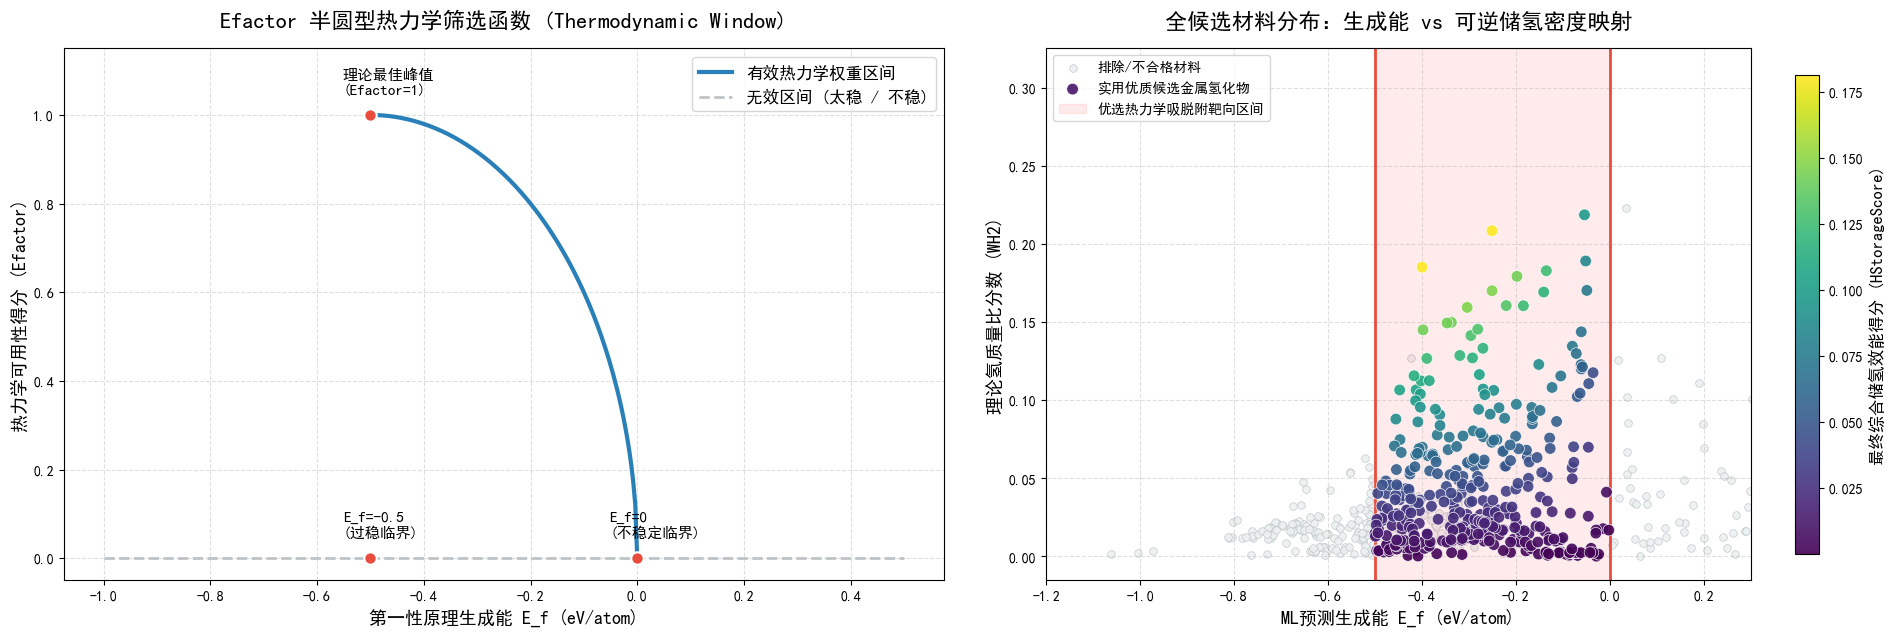

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

print("\n==========================================")
print(" 🌌 阶段 6：全候选材料分布：生成能 vs 可逆储氢密度映射大图")
print("==========================================")

fig = plt.figure(figsize=(20, 7), facecolor='white')

# 为了避免在 Notebook 环境中中文显示方块
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

# ----------- 图 A: Efactor 半圆权重函数 -----------
e_grid = np.linspace(-1.0, 0.5, 400)
ef_grid = np.array([efactor_semicircle(e) for e in e_grid])

ax1 = plt.subplot(1, 2, 1)
valid_mask = (e_grid >= -0.5) & (e_grid <= 0)
ax1.plot(e_grid[valid_mask], ef_grid[valid_mask], color='#2980b9', linewidth=3, label='有效热力学权重区间')

invalid_mask = ~valid_mask
ax1.plot(e_grid[invalid_mask], ef_grid[invalid_mask], color='#bdc3c7', linewidth=2, linestyle='--', label='无效区间 (太稳 / 不稳)')

key_points = [(-0.5, 0.0), (-0.5, 1.0), (0.0, 0.0)]
key_labels = ['E_f=-0.5\n(过稳临界)', '理论最佳峰值\n(Efactor=1)', 'E_f=0\n(不稳定临界)']
for (x, y), label in zip(key_points, key_labels):
    ax1.scatter(x, y, color='#e74c3c', s=80, zorder=3, edgecolor='white', linewidth=1.5)
    ax1.annotate(label, (x, y), xytext=(-20, 15), textcoords='offset points', fontsize=11, fontweight='bold')

ax1.set_title('Efactor 半圆型热力学筛选函数 (Thermodynamic Window)', fontsize=16, fontweight='bold', pad=15)
ax1.set_xlabel('第一性原理生成能 E_f (eV/atom)', fontsize=13)
ax1.set_ylabel('热力学可用性得分 (Efactor)', fontsize=13)
ax1.set_ylim(-0.05, 1.15)
ax1.grid(True, linestyle='--', alpha=0.4)
ax1.legend(loc='upper right', fontsize=12)

# ----------- 图 B: 全样本储氢评分分布 -----------
ax2 = plt.subplot(1, 2, 2)

# 分离有无潜力的材料作为不同图层 (数据来自阶段 5：score_df)
valid_df = score_df[score_df['is_practical'] == True]
invalid_df = score_df[score_df['is_practical'] == False]

# 背底层：不实用的材料（比如太稳了、或者有贵重金属/单一碱金属）
ax2.scatter(
    invalid_df['Predicted_Energy'], invalid_df['W_H2_Fraction'],
    color='#ecf0f1', alpha=0.9,
    edgecolors='#bdc3c7', linewidths=0.5, s=30, label='排除/不合格材料'
)

# 核心层：实用候选金属氢化物
sc = ax2.scatter(
    valid_df['Predicted_Energy'], valid_df['W_H2_Fraction'],
    c=valid_df['HStorageScore'], cmap='viridis', alpha=0.9,
    edgecolors='white', linewidths=0.5, s=70, zorder=3, label='实用优质候选金属氢化物'
)

ax2.axvline(-0.5, color='#e74c3c', linestyle='-', linewidth=2)
ax2.axvline(0.0, color='#e74c3c', linestyle='-', linewidth=2)
ax2.axvspan(-0.5, 0.0, alpha=0.08, color='red', label='优选热力学吸脱附靶向区间')

cbar = plt.colorbar(sc, ax=ax2, shrink=0.9)
cbar.set_label('最终综合储氢效能得分 (HStorageScore)', fontsize=12)

ax2.set_title('全候选材料分布：生成能 vs 可逆储氢密度映射', fontsize=16, fontweight='bold', pad=15)
ax2.set_xlabel('ML预测生成能 E_f (eV/atom)', fontsize=13)
ax2.set_ylabel('理论氢质量比分数 (WH2)', fontsize=13)
ax2.set_xlim(-1.2, 0.3)
ax2.legend(loc='upper left', fontsize=10, frameon=True)
ax2.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout(pad=3.0)
plt.show()